# Market Conditions and Price Forecasting for Carriage Services, Inc. (NYSE: CSV)
**Unsupervised clustering of daily trading behaviour and ARIMA forecasting, January 2017 – September 2026**

Module: Machine Learning for Business, HDip in Science in Data Analytics for Business, CCT College Dublin
Data: Yahoo Finance historical prices for ticker CSV, <https://finance.yahoo.com/quote/CSV/history/>

| Part of the brief | Where it is answered |
|---|---|
| Part 1: introduction, motivation, objectives, dataset rationale | Section 1 |
| Part 2: two clustering algorithms, silhouette and Davies–Bouldin comparison | Section 4 |
| Part 3: time-series exploration, ARIMA/SARIMA, evaluation, strengths and limitations | Section 5 |
| Part 4: interpretation, visualisations, conclusions, references | Sections 3, 6, 7 (poster and presentation are separate files) |

## 1. Introduction

### 1.1 Problem domain and motivation
Stock prices are a typical example of time-ordered business data. Every trading day gives us several measurements (open, high, low, close, volume), and the sequence of days forms a time series.

Two questions are useful to analysts and investors:
1. **Does the stock behave in different "modes" over time?** For example, quiet days versus busy, volatile days. Clustering can find such groups without needing any labels (Iqbal, n.d.a), and the lecture notes list market segmentation and anomaly detection as uses of clustering (Iqbal, n.d.c).
2. **Can past prices help forecast future prices?** Lecture 5 uses stock prices as an example of a non-stationary series. Such a series has to be differenced before an ARIMA model can be used (Iqbal, n.d.b; Iqbal, n.d.d; Pal and Prakash, 2017).

**Company.** Carriage Services, Inc. provides funeral home and cemetery services in the United States. It trades on the NYSE under the ticker CSV, and Yahoo Finance classifies it as Consumer Cyclical / Personal Services (Yahoo Finance, 2026b).

### 1.2 Research question
> *Can daily trading days for Carriage Services (CSV) between January 2017 and September 2026 be grouped into meaningful market-condition clusters using features that describe price movement, intraday range, volatility and relative trading volume? And can an ARIMA-family model forecast the daily closing price better than simple naïve baselines on data it has not seen?*

### 1.3 Objectives
1. Download, clean and document the CSV daily dataset so the analysis can be reproduced.
2. Create and explore features that describe daily behaviour.
3. Cluster the trading days with **K-Means** and **Agglomerative (hierarchical) clustering**, choosing the number of clusters with evidence.
4. Compare the two algorithms with the **silhouette score**, the **Davies–Bouldin Index**, cluster sizes, stability and interpretability, and pick a preferred solution.
5. Analyse the closing price as a time series (trend, stationarity, seasonality, ACF/PACF) and select ARIMA/SARIMA orders.
6. Evaluate forecasts on a **chronological** holdout against naïve baselines using MAE, RMSE and MAPE.
7. Interpret both parts together and state the limitations honestly.

### 1.4 Why this dataset?
- It comes from the source required by the assessment: the Yahoo Finance page for CSV (Yahoo Finance, 2026a). The module itself shows how to download Yahoo data with `yfinance` (*yahooFianance.ipynb*).
- About ten years of daily data (2,449 trading days, checked in Section 2) is enough for both clustering and a time-series train/test split.
- It has a mix of continuous price variables and a count variable (volume). These can be turned into behaviour features for clustering, and they give a clear forecasting target (Close).
- **Limitations:** it covers one company and has no external information (news, financial results, market index), so we can describe and forecast but not explain causes. This analysis is **not** investment advice.

### 1.5 Libraries used
We use the same libraries as the module tutorials wherever possible. Three tools go beyond the tutorials, and they are marked **(extension)**:
- `davies_bouldin_score`: the lecture gives the formula (Lecture 3, p. 19) but no code.
- `adjusted_rand_score`: used to measure how stable the clusters are.
- `acorr_ljungbox`: a formal test for leftover autocorrelation in residuals. The course only shows the residual correlogram.

All three come from the same scikit-learn / statsmodels libraries used in the course.

#### Step 1.6
**Why this step?** We load all libraries in one place so it is clear what the notebook depends on. We also fix a random seed, so K-Means gives the same answer every time the notebook runs. Printing the versions helps anyone who wants to reproduce the results.

In [1]:
import warnings
warnings.filterwarnings('ignore')        # hide library warnings, as in the module tutorials

import os
import json
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             mean_absolute_error, mean_squared_error)
from scipy.cluster.hierarchy import linkage, dendrogram

import statsmodels
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
import sklearn, scipy

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = 'figures'                       # every chart is also saved here for the poster
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight')

print('Python', platform.python_version())
for lib in (pd, np, sklearn, scipy, statsmodels, yf):
    print(f'{lib.__name__:<12}{lib.__version__}')

Python 3.14.0
pandas      2.3.3
numpy       2.4.2
sklearn     1.8.0
scipy       1.17.1
statsmodels 0.15.0
yfinance    1.7.0


---
## 2. Data collection and cleaning

#### Step 2.1
**Why this step?** We download the data from Yahoo Finance with `yfinance`, using the exact ticker from the assessment (CSV) and the agreed period **2 January 2017 – 30 September 2026**.

Four details matter:
- `yfinance` treats the `end` date as *exclusive*, so we pass 1 October 2026 to include 30 September.
- `auto_adjust=False` keeps both **Close** and **Adj Close**, the same columns as on the Yahoo web page.
- We save a **dated CSV snapshot** and a small metadata file, and every later run reads the snapshot. Yahoo can revise historical data (for example Adj Close after new dividends), so the snapshot keeps our results reproducible.
- `yfinance` is not an official Yahoo product. Its documentation says it is for research and educational purposes and that the Yahoo Finance API is for personal use only (Aroussi, n.d.). This coursework is non-commercial.

In [2]:
TICKER = 'CSV'
SOURCE_URL = 'https://finance.yahoo.com/quote/CSV/history/'
START = '2017-01-02'
END_INCLUSIVE = '2026-09-30'
END_EXCLUSIVE = '2026-10-01'             # yfinance does not include the end date itself

SNAPSHOT = f'data/{TICKER}_daily_{START}_{END_INCLUSIVE}.csv'
META = SNAPSHOT.replace('.csv', '_metadata.json')

if not os.path.exists(SNAPSHOT):
    downloaded = yf.download(TICKER, start=START, end=END_EXCLUSIVE, interval='1d',
                             auto_adjust=False, actions=True, progress=False, multi_level_index=False)
    if downloaded is None or downloaded.empty:
        raise RuntimeError('No data returned - check the ticker or the internet connection.')
    os.makedirs('data', exist_ok=True)
    downloaded.to_csv(SNAPSHOT)
    metadata = {'ticker': TICKER, 'source_url': SOURCE_URL,
                'requested_start_inclusive': START, 'requested_end_inclusive': END_INCLUSIVE,
                'interval': '1d', 'auto_adjust': False,
                'download_timestamp_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
                'yfinance_version': yf.__version__,
                'access_conditions': ('yfinance is not affiliated with or endorsed by Yahoo; intended for research and '
                                      'educational purposes; Yahoo! Finance API intended for personal use only; '
                                      "data use is subject to Yahoo's terms of use.")}
    with open(META, 'w') as f:
        json.dump(metadata, f, indent=2)
    print('Downloaded new snapshot:', SNAPSHOT)
else:
    print('Using saved snapshot:', SNAPSHOT)

with open(META) as f:
    metadata = json.load(f)
print(json.dumps(metadata, indent=2))

Using saved snapshot: data/CSV_daily_2017-01-02_2026-09-30.csv
{
  "ticker": "CSV",
  "source_url": "https://finance.yahoo.com/quote/CSV/history/",
  "requested_start_inclusive": "2017-01-02",
  "requested_end_inclusive": "2026-09-30",
  "interval": "1d",
  "auto_adjust": false,
  "download_timestamp_utc": "2026-10-21T00:11:10+00:00",
  "yfinance_version": "1.7.0",
  "access_conditions": "yfinance is not affiliated with or endorsed by Yahoo; intended for research and educational purposes; Yahoo! Finance API intended for personal use only; data use is subject to Yahoo's terms of use."
}


**What the output shows.** The data was downloaded on **21 October 2026** and saved as a snapshot. The metadata records the ticker, the URL, the requested dates and the access conditions, so anyone checking the work can see exactly where the data came from and when.

#### Step 2.2
**Why this step?** Before cleaning anything, we look at the raw file: how many rows and columns it has, what the columns are called and which data types pandas assigned. This tells us what needs fixing; for example, dates are read as plain text.

In [3]:
raw = pd.read_csv(SNAPSHOT)
print('Raw shape:', raw.shape)
print(raw.dtypes)
raw.head()

Raw shape: (2449, 9)
Date             object
Adj Close       float64
Close           float64
Dividends       float64
High            float64
Low             float64
Open            float64
Stock Splits    float64
Volume            int64
dtype: object


,Date,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,2017-01-03,25.1597,28.5300,0.0000,28.8600,28.2500,28.8600,0.0000,107900
1,2017-01-04,25.1332,28.5000,0.0000,28.8800,28.2600,28.6600,0.0000,130100
2,2017-01-05,24.9392,28.2800,0.0000,28.7600,28.0000,28.4500,0.0000,93400
3,2017-01-06,24.8422,28.1700,0.0000,28.6700,28.0600,28.3200,0.0000,129900
4,2017-01-09,24.2690,27.5200,0.0000,28.2400,27.5200,28.0400,0.0000,79300


**What the output shows.** The raw file has **2,449 rows and 9 columns**: Date plus eight fields (Adj Close, Close, Dividends, High, Low, Open, Stock Splits, Volume). Prices are decimals (`float64`) and volume is a whole number (`int64`). `Date` was read as text (`object`), so it must be converted before any time-series work.

#### Step 2.3
**Why this step?** Time-series methods need a proper date type and the rows in time order. We convert `Date` to datetime, sort by date, and check for duplicate dates, because the same day appearing twice would distort returns and rolling statistics.

In [4]:
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

n_duplicates = df.duplicated(subset='Date').sum()
df = df.drop_duplicates(subset='Date')
print('Duplicate dates found:', n_duplicates)
print('Date type is now:', df['Date'].dtype)

Duplicate dates found: 0
Date type is now: datetime64[ns]


**What the output shows.** There are **no duplicate dates**, and `Date` is now a proper datetime column in chronological order.

#### Step 2.4
**Why this step?** Missing or impossible values (negative prices, a High below the Low, and so on) would break the feature formulas and the models. We count them explicitly, so that any rows we remove are visible and explained rather than silently deleted.

In [5]:
price_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close']

print('Missing values per column:')
print(df.isna().sum().to_string())

validity_checks = {
    'price <= 0':                 (df[price_cols] <= 0).any(axis=1).sum(),
    'volume < 0':                 (df['Volume'] < 0).sum(),
    'volume = 0':                 (df['Volume'] == 0).sum(),
    'High < Low':                 (df['High'] < df['Low']).sum(),
    'High below Open or Close':   (df['High'] < df[['Open', 'Close']].max(axis=1)).sum(),
    'Low above Open or Close':    (df['Low'] > df[['Open', 'Close']].min(axis=1)).sum(),
}
print('\nInvalid rows per check:')
for check, count in validity_checks.items():
    print(f'  {check:<26}{count}')

Missing values per column:
Date            0
Adj Close       0
Close           0
Dividends       0
High            0
Low             0
Open            0
Stock Splits    0
Volume          0

Invalid rows per check:
  price <= 0                0
  volume < 0                0
  volume = 0                0
  High < Low                0
  High below Open or Close  0
  Low above Open or Close   0


**What the output shows.** There are **no missing values and no invalid rows** in any check. This is unusual for real data, but it is what Yahoo returned. Nothing had to be deleted or filled in, so the full dataset is kept.

#### Step 2.5
**Why this step?** The assessment requires data from the **last ten years**. We check the first and last dates actually returned and compare them with the date ten years before the download.

In [6]:
download_date = pd.Timestamp(metadata['download_timestamp_utc'][:10])
ten_year_limit = download_date - pd.DateOffset(years=10)
first_day, last_day = df['Date'].min(), df['Date'].max()

print('First observation :', first_day.date())
print('Last observation  :', last_day.date())
print('Download date     :', download_date.date(), '-> ten-year limit:', ten_year_limit.date())
print('Inside ten-year window:', first_day >= ten_year_limit)

First observation : 2017-01-03
Last observation  : 2026-09-30
Download date     : 2026-10-21 -> ten-year limit: 2016-10-21
Inside ten-year window: True


**What the output shows.** Yahoo returned no row for 2 January 2017 because the market was closed for the New Year holiday, so the **first observation is 3 January 2017**. The **last is 30 September 2026**. The earliest allowed date is 21 October 2016, so the data is **inside the ten-year window**.

#### Step 2.6
**Why this step?** Stock markets close at weekends and on holidays, so gaps between dates are normal. A gap of a week or more could mean missing data, so we count the gaps between consecutive trading days and the number of days per year.

In [7]:
gap_days = df['Date'].diff().dt.days
print('Gap between consecutive rows (calendar days) -> count')
print(gap_days.value_counts().sort_index().to_string())
print('\nTrading days per year:')
print(df['Date'].dt.year.value_counts().sort_index().to_string())

Gap between consecutive rows (calendar days) -> count
Date
1.0000    1914
2.0000      26
3.0000     441
4.0000      67

Trading days per year:
Date
2017    251
2018    251
2019    252
2020    253
2021    252
2022    251
2023    250
2024    252
2025    250
2026    187


**What the output shows.** Most consecutive rows are 1 day apart (weekdays) or 3 days apart (weekends). The 2- and 4-day gaps are single-day holidays and long weekends. The longest gap is 4 days, so **there is no missing block of data**. Full years have 250–253 trading days, which is normal for US markets. 2026 has 187 because it stops at the end of September.

#### Step 2.7
**Why this step?** `yfinance` also returns two event columns, `Dividends` and `Stock Splits`. We check what they contain before deciding whether they belong in the analysis.

In [8]:
print('Days with a dividend:', (df['Dividends'] > 0).sum())
print('Days with a split   :', (df['Stock Splits'] > 0).sum())
print('Dividend amounts paid:', sorted(df.loc[df['Dividends'] > 0, 'Dividends'].round(4).unique()))

Days with a dividend: 39
Days with a split   : 0
Dividend amounts paid: [np.float64(0.05), np.float64(0.075), np.float64(0.088), np.float64(0.1), np.float64(0.113)]


**What the output shows.** There were **39 dividend days** (paid quarterly, between 0.05 and 0.113 USD per share) and **no stock splits**. `Stock Splits` is always zero, so it carries no information and is dropped. `Dividends` is an occasional event, not a daily market measurement, and its effect is already built into **Adj Close**. So we keep the dividend dates for reference but leave them out of the modelling table.

#### Step 2.8
**Why this step?** To make sure the download is genuine, we compare a few rows with the values shown on the Yahoo Finance web page when we checked it in a browser on 21 October 2026.

In [9]:
web_page_values = {                       # Open, High, Low, Close, Volume as displayed on the web page
    '2026-09-30': (31.26, 31.42, 30.73, 31.17, 157900),
    '2026-09-29': (31.37, 31.82, 30.83, 30.98, 235900),
    '2026-09-28': (31.88, 32.01, 30.88, 31.38, 201000),
}
for day, expected in web_page_values.items():
    row = df.loc[df['Date'] == day, ['Open', 'High', 'Low', 'Close', 'Volume']].iloc[0]
    prices_match = np.allclose(row.values[:4].astype(float), expected[:4], atol=0.006)
    volume_match = int(row['Volume']) == expected[4]
    print(day, 'matches' if prices_match and volume_match else 'DOES NOT MATCH')

2026-09-30 matches
2026-09-29 matches
2026-09-28 matches


**What the output shows.** All three rows **match the Yahoo web page exactly**. This confirms that the downloaded data is the real data from the required source.

#### Step 2.9
**Why this step?** We now build the final clean table: Date becomes the index, and we keep the six market variables. `Stock Splits` is dropped and the dividend dates are stored separately (reasons given in step 2.7).

In [10]:
dividend_dates = df.loc[df['Dividends'] > 0, ['Date', 'Dividends']].set_index('Date')
data = df.set_index('Date')[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]

print(f'Before cleaning: {raw.shape[0]} rows x {raw.shape[1]} columns')
print(f'After cleaning : {data.shape[0]} rows x {data.shape[1]} columns + Date index')
data.describe().T

Before cleaning: 2449 rows x 9 columns
After cleaning : 2449 rows x 6 columns + Date index


,count,mean,std,min,25%,50%,75%,max
Open,"2,449.0000",31.2822,9.8095,14.0400,24.4600,28.0700,38.7900,65.9100
High,"2,449.0000",31.7167,9.9490,14.3200,24.7300,28.4000,39.3400,66.3300
Low,"2,449.0000",30.8537,9.6905,13.5400,24.1100,27.7600,38.3100,64.8300
Close,"2,449.0000",31.2708,9.8157,13.8000,24.3900,28.0500,38.8000,65.9100
Adj Close,"2,449.0000",29.5735,9.9301,12.6590,22.2476,26.4004,37.7807,61.8628
Volume,"2,449.0000","113,209.8816","77,045.2769","11,700.0000","68,200.0000","92,300.0000","133,500.0000","1,035,700.0000"


**What the output shows.** The clean dataset has **2,449 rows × 6 columns** (Open, High, Low, Close, Adj Close, Volume) **plus the Date index**. No rows were removed during cleaning. Close ranged from 13.80 to 65.91 USD, and daily volume from 11,700 to 1,035,700 shares.

**Note on the seven-column requirement:** the source provides 7 columns if Date is counted, or 6 analytical variables without it. Section 3 adds 4 *derived* features, giving 10 variables used in the analysis plus Date. We have not created columns just to reach a number. Whether derived features count towards the requirement should be **confirmed with the lecturer**.

---
## 3. Feature engineering and exploratory data analysis

### The original variables

| Column | Type | Meaning |
|---|---|---|
| Date (index) | datetime | trading day on the NYSE |
| Open, High, Low, Close | continuous (USD) | first, highest, lowest and last traded price of the day |
| Adj Close | continuous (USD) | Close adjusted backwards for dividends |
| Volume | discrete count | number of shares traded |

All five price columns follow the same price level. If we clustered on them directly, days would be grouped by *how expensive the share was*, which is really grouping by date, not by *how the market behaved*. So for clustering we create four features that describe behaviour and don't depend on the price level. These are **derived** features, not extra original columns.

#### Step 3.1
**Why this step?** **Daily log return** measures how much the price moved from one day to the next:
$r_t = \ln(\text{AdjClose}_t / \text{AdjClose}_{t-1})$.

- We use **Adj Close** so that the drop on a dividend day is not counted as a loss.
- We use the **log** form because Lecture 5 (p. 11) recommends logging for price series, and log returns add up over time. For daily moves, log returns and percentage returns are almost identical, so we keep only one of them to avoid duplicate features.

In [11]:
features = pd.DataFrame(index=data.index)
features['log_return'] = np.log(data['Adj Close'] / data['Adj Close'].shift(1))
features['log_return'].head(3)

Date
2017-01-03       NaN
2017-01-04   -0.0011
2017-01-05   -0.0077
Name: log_return, dtype: float64

**What the output shows.** The first value is missing (NaN), because the first day has no previous day to compare with. We deal with this before clustering.

#### Step 3.2
**Why this step?** **Intraday range** shows how far the price swung *within* a day, relative to the price level:
$(\text{High}_t - \text{Low}_t)/\text{Close}_t$.

A wide range can signal uncertainty even when the stock closes almost unchanged.

In [12]:
features['intraday_range'] = (data['High'] - data['Low']) / data['Close']

#### Step 3.3
**Why this step?** **20-day rolling volatility** is the standard deviation of the log returns over the last 20 trading days, roughly one month. Tutorial 5(a) uses the same rolling-window idea for the mean and variance. A single day's return is noisy; the rolling volatility tells us whether the stock is currently in a calm or a turbulent period.

In [13]:
VOL_WINDOW = 20   # about one trading month
features['volatility_20d'] = features['log_return'].rolling(VOL_WINDOW).std()

#### Step 3.4
**Why this step?** **Relative volume** compares today's volume with the average of the *previous* 20 days:
$\ln(\text{Volume}_t / \text{mean}(\text{Volume}_{t-20 \ldots t-1}))$.

Raw volume tells us little on its own because "normal" volume changes over the years; relative volume shows whether trading is *unusually* busy or quiet. We take the log so that doubling (+0.69) and halving (−0.69) are symmetric.

In [14]:
features['rel_volume_20d'] = np.log(data['Volume'] / data['Volume'].rolling(VOL_WINDOW).mean().shift(1))

FEATURES = ['log_return', 'intraday_range', 'volatility_20d', 'rel_volume_20d']
print('Missing values caused by the look-back windows:')
print(features[FEATURES].isna().sum().to_string())
features[FEATURES].describe().T

Missing values caused by the look-back windows:
log_return         1
intraday_range     0
volatility_20d    20
rel_volume_20d    20


,count,mean,std,min,25%,50%,75%,max
log_return,"2,448.0000",0.0001,0.0239,-0.3152,-0.0109,0.0000,0.0104,0.1992
intraday_range,"2,449.0000",0.0281,0.0185,0.0065,0.0179,0.0239,0.0325,0.2812
volatility_20d,"2,429.0000",0.0207,0.0122,0.0055,0.0134,0.0173,0.0226,0.0785
rel_volume_20d,"2,429.0000",-0.1027,0.4990,-1.9355,-0.4350,-0.1439,0.1698,2.5609


**What the output shows.** The rolling features are missing for the first 20 days (there isn't enough history yet), and the return is missing for the first day. Some typical values:
- **Log return:** the average is almost zero, and a typical daily move (one standard deviation) is about 2.4%. The worst day was −31.5%, the best +19.9%.
- **Intraday range:** on a typical (median) day the price moves about 2.4% between its low and high.
- **20-day volatility:** varies from 0.55% to 7.85%, so some periods are far more turbulent than others.
- **Relative volume:** usually a little below zero, because the volume average is pulled up by occasional very busy days.

#### Step 3.5
**Why this step?** First we look at the whole price history. It shows the long-term trend and any big turning points that the clustering and forecasting will need to deal with. The 50- and 200-day moving averages (Lecture 5, p. 10) smooth out the daily noise; they are only for the chart, not model inputs.

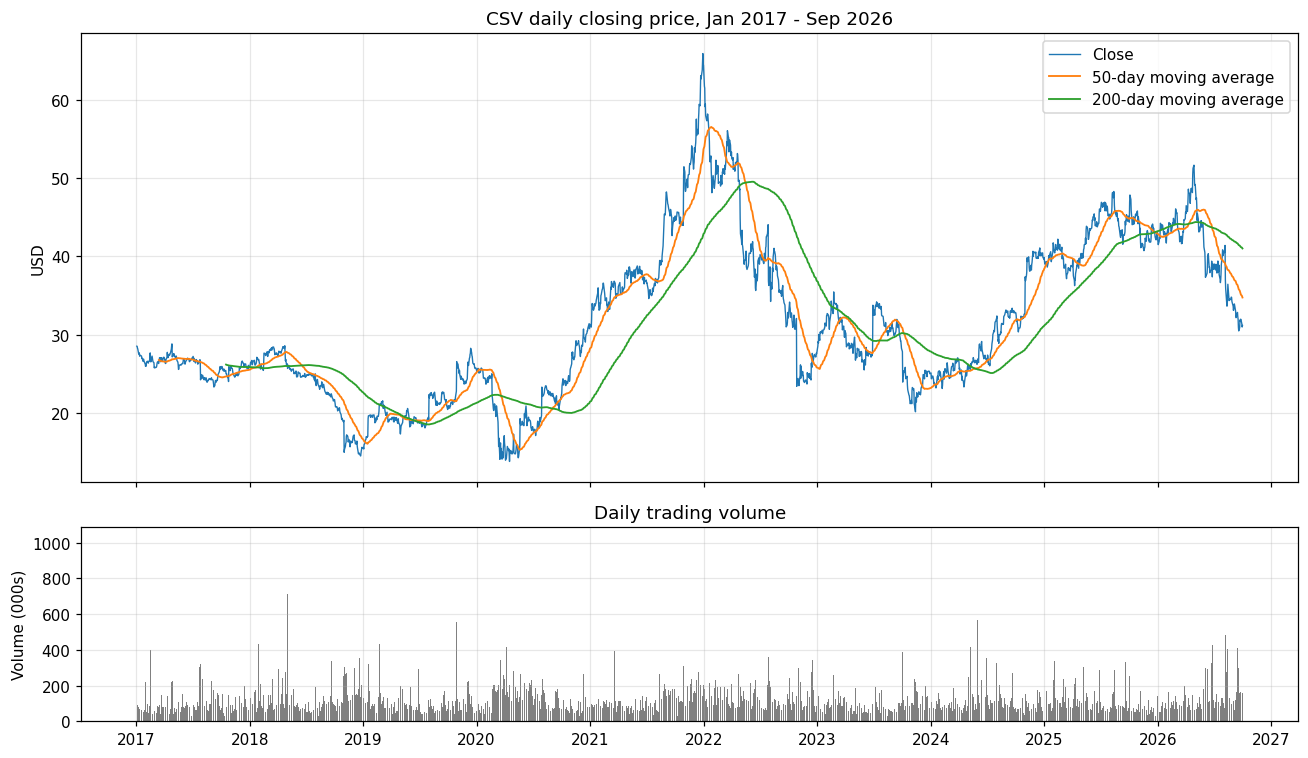

In [15]:
ma50 = data['Close'].rolling(50).mean()
ma200 = data['Close'].rolling(200).mean()

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ax[0].plot(data.index, data['Close'], lw=0.9, label='Close')
ax[0].plot(ma50.index, ma50, lw=1.2, label='50-day moving average')
ax[0].plot(ma200.index, ma200, lw=1.2, label='200-day moving average')
ax[0].set_ylabel('USD'); ax[0].set_title('CSV daily closing price, Jan 2017 - Sep 2026'); ax[0].legend()
ax[1].bar(data.index, data['Volume'] / 1000, width=1.5, color='grey')
ax[1].set_ylabel('Volume (000s)'); ax[1].set_title('Daily trading volume')
plt.tight_layout(); savefig('C3_price_volume.png'); plt.show()

**What the output shows.** The price has **no stable long-term trend**. It drifted down from about 28 USD (2017) to lows around 14–15 USD (late 2018 and 2020), rose sharply to its peak of 65.91 USD around the end of 2021, fell back to the 20s in 2023, recovered into the 40s in 2025 and dropped to about 31 USD by September 2026. The moving averages show these swings clearly. Volume shows occasional large spikes on top of a fairly stable base. A changing level like this already suggests the price is **not stationary**, which Section 5 tests formally.

#### Step 3.6
**Why this step?** The distribution of daily returns shows how often large moves happen. If extreme days are much more common than a normal distribution would predict, that affects both the clustering (outliers pull the clusters) and the forecasting (prediction intervals rely on the normal assumption).

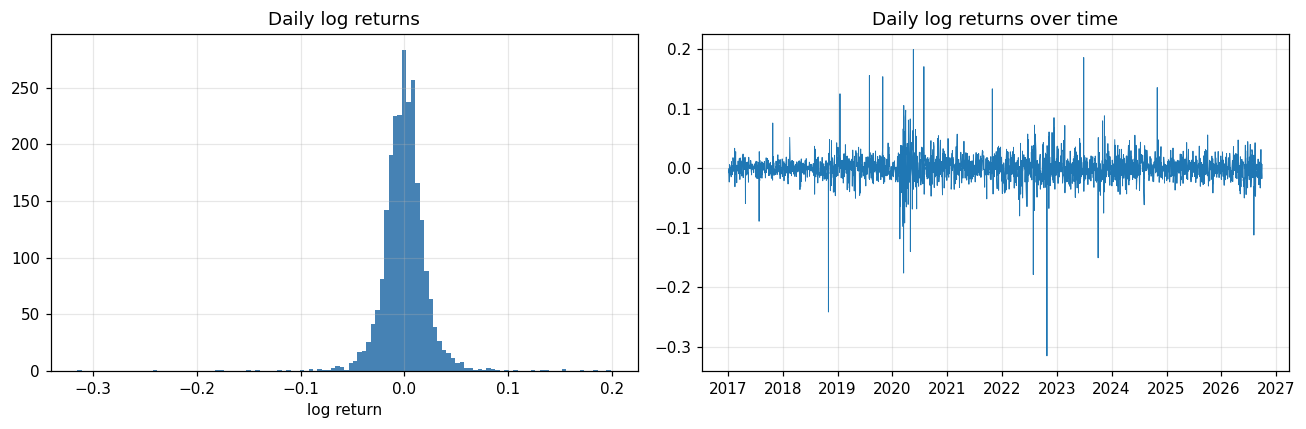

Mean 0.00009 | Std 0.02390 | Skewness -0.915 | Excess kurtosis 27.386
Days beyond 3 standard deviations: 1.31% (a normal distribution would give about 0.27%)


In [16]:
returns = features['log_return'].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(returns, bins=120, color='steelblue'); ax[0].set_title('Daily log returns'); ax[0].set_xlabel('log return')
ax[1].plot(returns.index, returns, lw=0.6); ax[1].set_title('Daily log returns over time')
plt.tight_layout(); savefig('C4_returns.png'); plt.show()

share_extreme = (np.abs(returns - returns.mean()) > 3 * returns.std()).mean()
print(f'Mean {returns.mean():.5f} | Std {returns.std():.5f} | Skewness {returns.skew():.3f} | Excess kurtosis {returns.kurt():.3f}')
print(f'Days beyond 3 standard deviations: {share_extreme:.2%} (a normal distribution would give about 0.27%)')

**What the output shows.** Returns are centred on zero (mean 0.00009) with a standard deviation of 0.0239. The distribution has a long left tail (**skewness −0.915**) and very **heavy tails (excess kurtosis 27.4)**: 1.31% of days move by more than 3 standard deviations, about **five times** what a normal distribution would predict (0.27%). So big jumps are much more common than "normal". We must keep this in mind: extreme days can distort clusters, and ARIMA's prediction intervals assume normal errors.

#### Step 3.7
**Why this step?** Next we check whether the *amount* of movement changes over time. The rolling volatility and relative volume charts, plus a yearly summary table, show whether there are calm and turbulent periods: exactly the kind of structure the clustering is meant to find.

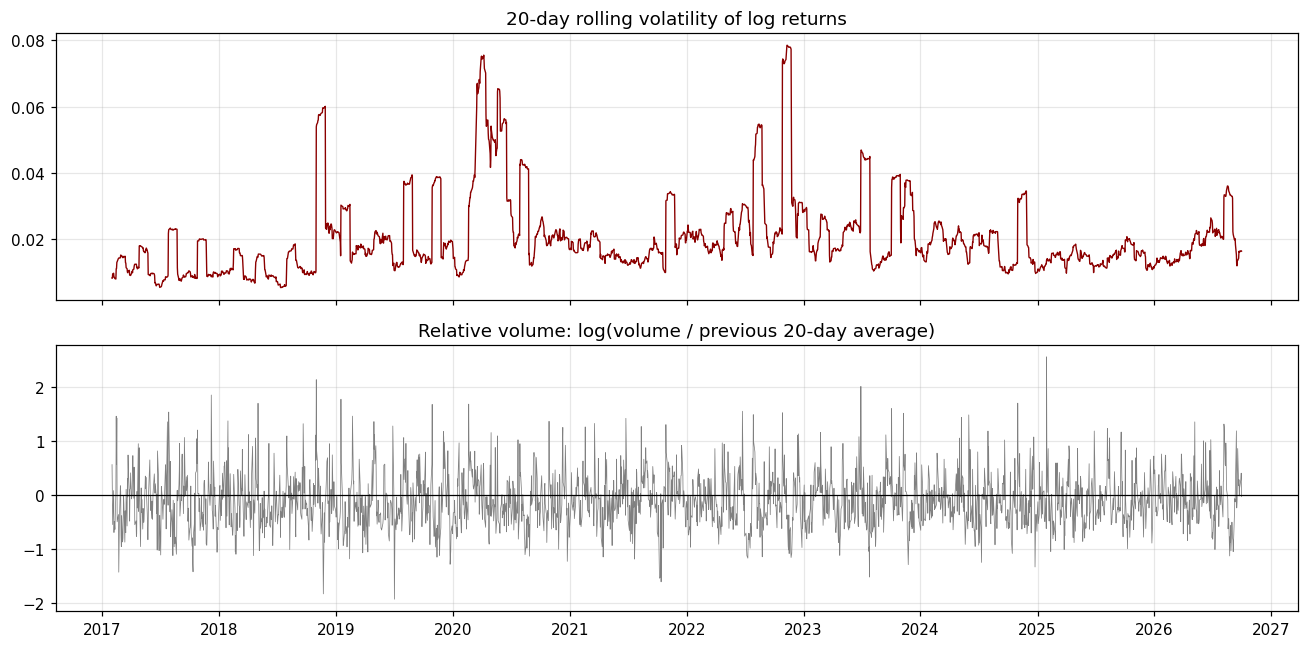

,mean_close,annualised_volatility,mean_volume
Date,,,
2017,26.0388,0.2065,"97,492.4303"
2018,23.5085,0.3291,"121,019.1235"
2019,20.8633,0.3572,"101,630.1587"
2020,21.7043,0.5915,"136,238.3399"
2021,41.1599,0.2951,"120,588.4921"
2022,40.0431,0.5323,"128,367.3307"
2023,28.6857,0.4122,"96,617.6000"
2024,29.8378,0.3102,"103,844.4444"
2025,42.5658,0.2336,"104,470.0000"


In [17]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(features.index, features['volatility_20d'], lw=0.9, color='darkred')
ax[0].set_title('20-day rolling volatility of log returns')
ax[1].plot(features.index, features['rel_volume_20d'], lw=0.5, color='grey'); ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_title('Relative volume: log(volume / previous 20-day average)')
plt.tight_layout(); savefig('C5_volatility_volume.png'); plt.show()

yearly_summary = pd.DataFrame({
    'mean_close': data['Close'].groupby(data.index.year).mean(),
    'annualised_volatility': features['log_return'].groupby(features.index.year).std() * np.sqrt(252),
    'mean_volume': data['Volume'].groupby(data.index.year).mean(),
})
yearly_summary

**What the output shows.** Volatility clearly **changes over time**. Annualised volatility was lowest in 2017 (0.21) and 2025 (0.23) and highest in 2020 (0.59) and 2022 (0.53). The rolling chart shows these as separate bursts. Average volume was also highest in 2020 (about 136,000 shares a day). This supports the idea behind the clustering, that there are calm and turbulent periods. It is also a warning for ARIMA, which assumes the size of the errors stays constant.

#### Step 3.8
**Why this step?** A correlation heatmap shows which variables carry the same information. That helps justify the feature choice: we want clustering features that are not just copies of each other.

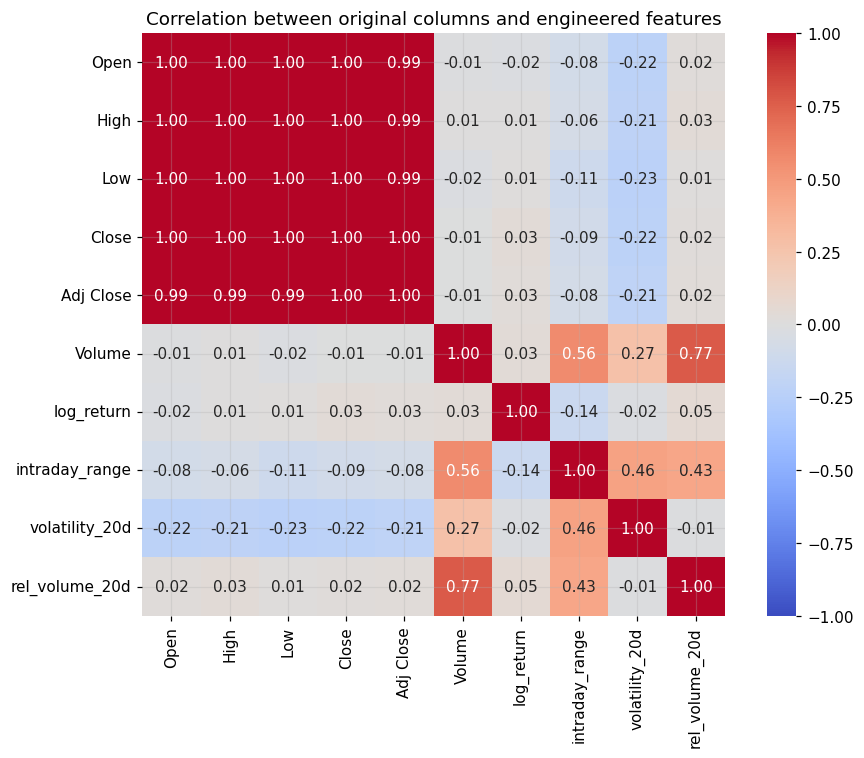

In [18]:
corr = pd.concat([data, features[FEATURES]], axis=1).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation between original columns and engineered features')
plt.tight_layout(); savefig('C6_correlation.png'); plt.show()

**What the output shows.** - **The five price columns are almost perfectly correlated** (0.99–1.00). They tell us the same thing (the price level), which is why we don't use them as clustering features.
- Our four engineered features are only weakly related to the price level (|r| ≤ 0.23) and only moderately related to each other: the strongest pair is intraday range and volatility at 0.46. So each feature adds different information.
- Volume is strongly linked to relative volume (0.77) and to intraday range (0.56): busy days tend to have wider price swings.

These are correlations only. They don't show that volume *causes* bigger price moves.

#### Step 3.9
**Why this step?** Unusual observations (anomalies) are worth inspecting before modelling. We list the ten biggest daily moves to see what extreme days look like. We keep them in the data because they are real market events, not data errors.

In [19]:
biggest_moves = features.assign(abs_return=features['log_return'].abs()).nlargest(10, 'abs_return')
biggest_moves.join(data[['Close', 'Volume']])[['log_return', 'intraday_range', 'rel_volume_20d', 'Close', 'Volume']]

,log_return,intraday_range,rel_volume_20d,Close,Volume
Date,,,,,
2022-10-27,-0.3152,0.2145,1.5236,23.4000,514100
2018-11-01,-0.2415,0.2812,2.1374,14.9700,822500
2020-05-20,0.1992,0.1391,1.0940,19.2700,646800
2023-06-29,0.1856,0.0693,2.0133,33.7600,582600
2022-07-28,-0.1787,0.1208,1.4884,36.8400,358500
2020-03-16,-0.1761,0.1414,0.0487,14.0700,195700
2020-07-29,0.1704,0.1052,0.9496,23.3000,369500
2019-08-01,0.1556,0.1428,1.0618,22.3400,151400
2019-10-29,0.1535,0.1544,1.6787,26.5600,555000


**What the output shows.** The biggest daily moves were **−31.5% (27 Oct 2022)**, **−24.2% (1 Nov 2018)** and **+19.9% (20 May 2020)**. In 9 of the 10 cases trading volume was far above normal (relative volume above 0.9, i.e. roughly 2.5 times the previous month's average). The exception is 16 Mar 2020. We did not research the news behind these days, so we don't claim to know their causes. They are real observations and stay in the data.

#### Step 3.10
**Why this step?** Before assuming any seasonality, we check whether returns differ by calendar month or weekday. This is a quick visual check; the formal seasonality check for the forecasting target is in Section 5.

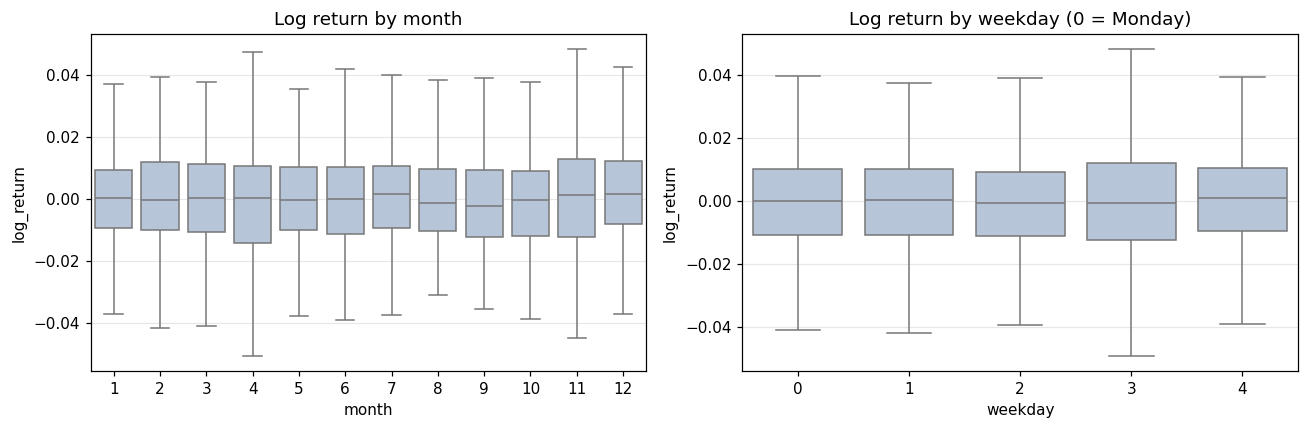

month,1,2,3,4,5,6,7,8,9,10,11,12
mean,0.0004,0.0004,-0.0009,-0.0019,0.0003,0.0007,0.0012,0.0001,-0.0016,-0.0000,0.0001,0.0026
std,0.0184,0.0207,0.0268,0.0246,0.0229,0.0236,0.0238,0.0227,0.0158,0.0347,0.0289,0.0181
count,202.0000,191.0000,219.0000,206.0000,212.0000,209.0000,212.0000,221.0000,204.0000,200.0000,184.0000,188.0000


In [20]:
calendar = returns.to_frame().assign(month=returns.index.month, weekday=returns.index.dayofweek)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=calendar, x='month', y='log_return', ax=ax[0], showfliers=False, color='lightsteelblue')
ax[0].set_title('Log return by month')
sns.boxplot(data=calendar, x='weekday', y='log_return', ax=ax[1], showfliers=False, color='lightsteelblue')
ax[1].set_title('Log return by weekday (0 = Monday)')
plt.tight_layout(); savefig('C8_calendar.png'); plt.show()

calendar.groupby('month')['log_return'].agg(['mean', 'std', 'count']).T

**What the output shows.** Average returns by month range from −0.0019 (April) to +0.0026 (December). That is tiny compared with the daily standard deviation (0.016–0.035), and the boxes overlap almost completely for both months and weekdays. So there is **no visible calendar pattern** in returns, and no reason so far to expect seasonality.

---
## 4. Unsupervised clustering of trading days (Part 2)

**Goal:** group trading days with similar behaviour, using the four features from Section 3.

**The two algorithms (both taught in the module):**
1. **K-Means** (Lecture 1, pp. 12–18; Tutorial 1). Each day is assigned to the nearest cluster centre (centroid, using Euclidean distance), and the centres are recalculated until they stop moving.
   - *Strengths:* simple, fast, and the centroids are easy to describe.
   - *Weaknesses:* we must choose k in advance, it assumes roughly round clusters of similar size, it is sensitive to outliers, and the result depends on the random starting centres (reduced with `n_init=10`).
2. **Agglomerative hierarchical clustering** (Lecture 2 Hierarchical, pp. 4–16; Tutorial 2). Every day starts as its own cluster, and the two closest clusters are merged again and again. The **linkage** method (single, complete, average or Ward) defines what "closest" means, and a **dendrogram** shows the merge history.
   - *Strengths:* no random start, and the dendrogram helps choose the number of clusters.
   - *Weaknesses:* merges can never be undone, it is slower and uses more memory, and the result depends strongly on the linkage.

**Evaluation metrics:**
- **Silhouette score** (Lecture 1, p. 10): $s = (b - a)/\max(a, b)$, from −1 to +1; **higher is better**. *a* is the average distance to points in the same cluster and *b* the average distance to the nearest other cluster.
- **Davies–Bouldin Index** (Lecture 3, pp. 19–20): the average, over clusters, of (spread of cluster i + spread of cluster j) / (distance between them), taking the most similar neighbour j each time; **lower is better**.

Both metrics reward compact, well-separated clusters, but in different ways: silhouette works point by point, DBI centroid by centroid. **Neither proves that clusters are meaningful**, so we also look at cluster sizes, stability and interpretation.

#### Step 4.1
**Why this step?** The rolling features are missing for the first 20 days and the return is missing for the first day. Clustering can't handle missing values, so we drop those 20 warm-up rows for this section only. That is under 1% of the data and doesn't affect the time-series section.

In [21]:
cluster_data = features[FEATURES].dropna()
print(f'Days available: {len(features)} | dropped (warm-up rows): {len(features) - len(cluster_data)} | used: {len(cluster_data)}')
print('Clustering period:', cluster_data.index.min().date(), 'to', cluster_data.index.max().date())

Days available: 2449 | dropped (warm-up rows): 20 | used: 2429
Clustering period: 2017-02-01 to 2026-09-30


#### Step 4.2
**Why this step?** Both algorithms use Euclidean distance, so a feature with a bigger spread would dominate the distances. For example, relative volume varies about 20 times more than log returns (see the summary in step 3.4). `StandardScaler` rescales each feature to mean 0 and standard deviation 1, as in Tutorial 3 Solution. We fit the scaler on all clustering rows: clustering here is descriptive, with no train/test split, so there is no test data to leak.

In [22]:
scaler = StandardScaler()
X = scaler.fit_transform(cluster_data)
print('Means after scaling:', X.mean(axis=0).round(3))
print('Std after scaling  :', X.std(axis=0).round(3))

Means after scaling: [ 0. -0.  0.  0.]
Std after scaling  : [1. 1. 1. 1.]


**What the output shows.** All four features now have mean 0 and standard deviation 1, so each contributes equally to the distance calculations.

#### Step 4.3
**Why this step?** To choose k for K-Means, we follow Tutorial 1: fit K-Means for k = 2 to 10 and record the SSE (elbow method), the silhouette score and the Davies–Bouldin Index. We also record the size of the smallest cluster, because a 'cluster' of only a handful of days is just a set of outliers, not a useful market condition.

In [23]:
K_VALUES = range(2, 11)
kmeans_scan = []
for k in K_VALUES:
    model = KMeans(n_clusters=k, n_init=10, max_iter=300, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    kmeans_scan.append({'k': k,
                        'SSE': model.inertia_,
                        'silhouette': silhouette_score(X, labels),
                        'davies_bouldin': davies_bouldin_score(X, labels),
                        'smallest_cluster_%': np.bincount(labels).min() / len(labels) * 100})
kmeans_scan = pd.DataFrame(kmeans_scan).set_index('k')
kmeans_scan

,SSE,silhouette,davies_bouldin,smallest_cluster_%
k,,,,
2,"7,502.3408",0.4917,1.4529,13.4212
3,"6,236.7297",0.2571,1.3923,7.0811
4,"5,219.5024",0.2648,1.2099,0.8646
5,"4,486.4107",0.2768,1.1111,0.8234
6,"3,963.5124",0.2645,1.1174,0.7822
7,"3,587.3840",0.2148,1.1563,0.5764
8,"3,279.8483",0.2301,1.1073,0.5352
9,"3,030.7012",0.2287,1.0969,0.5352
10,"2,791.2684",0.2339,1.0854,0.4117


#### Step 4.4
**Why this step?** Plotting the three measures side by side makes the trade-offs easier to see than the table alone.

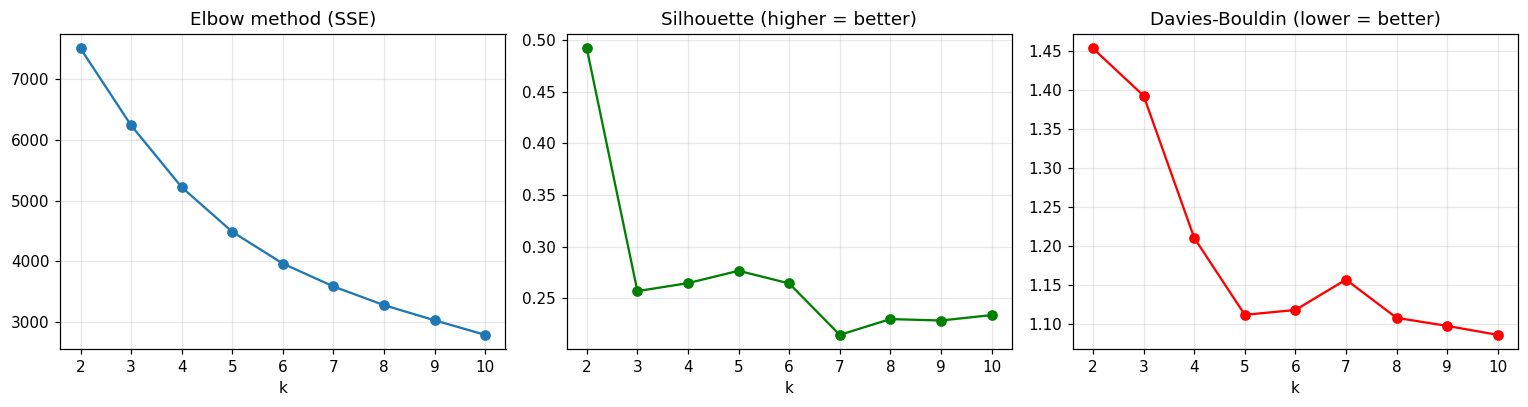

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(kmeans_scan.index, kmeans_scan['SSE'], 'o-'); ax[0].set_title('Elbow method (SSE)')
ax[1].plot(kmeans_scan.index, kmeans_scan['silhouette'], 'o-', c='green'); ax[1].set_title('Silhouette (higher = better)')
ax[2].plot(kmeans_scan.index, kmeans_scan['davies_bouldin'], 'o-', c='red'); ax[2].set_title('Davies-Bouldin (lower = better)')
for a in ax:
    a.set_xlabel('k')
plt.tight_layout(); savefig('D2_kmeans_selection.png'); plt.show()

**What the output shows.** The three measures don't agree:
- **SSE** falls smoothly as k grows, so there is no clear "elbow".
- **Silhouette** is clearly best at **k = 2 (0.492)**, falls to 0.257 at k = 3, and stays between 0.21 and 0.28 after that.
- **Davies–Bouldin** keeps improving (falling) as k grows: 1.453 at k = 2, 1.392 at k = 3, 1.085 at k = 10.

However, from **k = 4 the smallest cluster holds less than 1% of days** (0.86% at k = 4). K-Means is then splitting off a few extreme days as a separate "cluster", which isn't a useful market condition. So k = 2 or k = 3 are the realistic options.

#### Step 4.5
**Why this step?** For agglomerative clustering we also need to choose the **linkage**. Lecture 2 (p. 16) says different linkages give different clusters and there is no single best one. So we test all four linkages for k = 2 to 10, with the same metrics as for K-Means.

In [25]:
LINKAGES = ['ward', 'complete', 'average', 'single']
agglo_scan = []
for link in LINKAGES:
    for k in K_VALUES:
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X)
        agglo_scan.append({'linkage': link, 'k': k,
                           'silhouette': silhouette_score(X, labels),
                           'davies_bouldin': davies_bouldin_score(X, labels),
                           'smallest_cluster_%': np.bincount(labels).min() / len(labels) * 100})
agglo_scan = pd.DataFrame(agglo_scan)

for metric in ['silhouette', 'davies_bouldin', 'smallest_cluster_%']:
    print(f'\n{metric} (rows = k, columns = linkage)')
    display(agglo_scan.pivot(index='k', columns='linkage', values=metric).round(3))


silhouette (rows = k, columns = linkage)


linkage,average,complete,single,ward
k,,,,
2,0.8050,0.8050,0.8680,0.3340
3,0.7760,0.6890,0.8660,0.3120
4,0.7420,0.6880,0.7800,0.3140
5,0.6280,0.4640,0.7700,0.3150
6,0.6280,0.4080,0.7470,0.3080
7,0.5650,0.4070,0.7470,0.1690
8,0.5650,0.3330,0.7450,0.1740
9,0.5650,0.3320,0.7110,0.1870
10,0.5360,0.3300,0.7110,0.1950



davies_bouldin (rows = k, columns = linkage)


linkage,average,complete,single,ward
k,,,,
2,0.4890,0.4890,0.2380,1.6880
3,0.5860,0.6710,0.0900,1.4810
4,0.5760,0.6790,0.1690,1.2240
5,0.8090,1.2160,0.4580,1.1300
6,0.6730,0.9980,0.4090,1.1120
7,0.7660,0.9610,0.3720,1.2560
8,0.7090,1.0200,0.3470,1.1990
9,0.6650,1.0650,0.3450,1.1300
10,0.7520,1.0350,0.3320,1.1540



smallest_cluster_% (rows = k, columns = linkage)


linkage,average,complete,single,ward
k,,,,
2,0.4120,0.4120,0.0820,21.5730
3,0.0820,0.4120,0.0410,10.9920
4,0.0820,0.0820,0.0410,0.4120
5,0.0820,0.0820,0.0410,0.4120
6,0.0410,0.0820,0.0410,0.4120
7,0.0410,0.0820,0.0410,0.4120
8,0.0410,0.0820,0.0410,0.4120
9,0.0410,0.0820,0.0410,0.4120
10,0.0410,0.0820,0.0410,0.4120


**What the output shows.** This table shows why metrics alone can mislead:
- **Single, complete and average linkage** get very high silhouette scores (up to 0.868) and very low DBI values (down to 0.090), which looks excellent.
- But their smallest cluster holds only **0.04–0.41% of the days, i.e. 1 to 10 days**. They simply cut off a handful of extreme days and put everything else (~99%) into one big cluster. Lecture 2 (p. 16) notes that single linkage tends to leave outliers until the end.
- **Ward linkage** is the only one that gives balanced clusters: silhouette 0.334 (k = 2) and 0.312 (k = 3), with the smallest cluster at 21.6% and 11.0% of days. From k = 4 it also starts isolating a 10-day group (0.41%).

We therefore **choose Ward linkage**. It also minimises the variance within clusters, the same idea as K-Means, which makes the two algorithms fair to compare.

#### Step 4.6
**Why this step?** The dendrogram is the visual tool for hierarchical clustering taught in Lecture 2. Following Lecture 2 (p. 15), a sensible place to cut the tree is where there is a big vertical jump between merges. With 2,429 days the full tree would be unreadable, so we show only the last 30 merges and print the heights of the final ones.

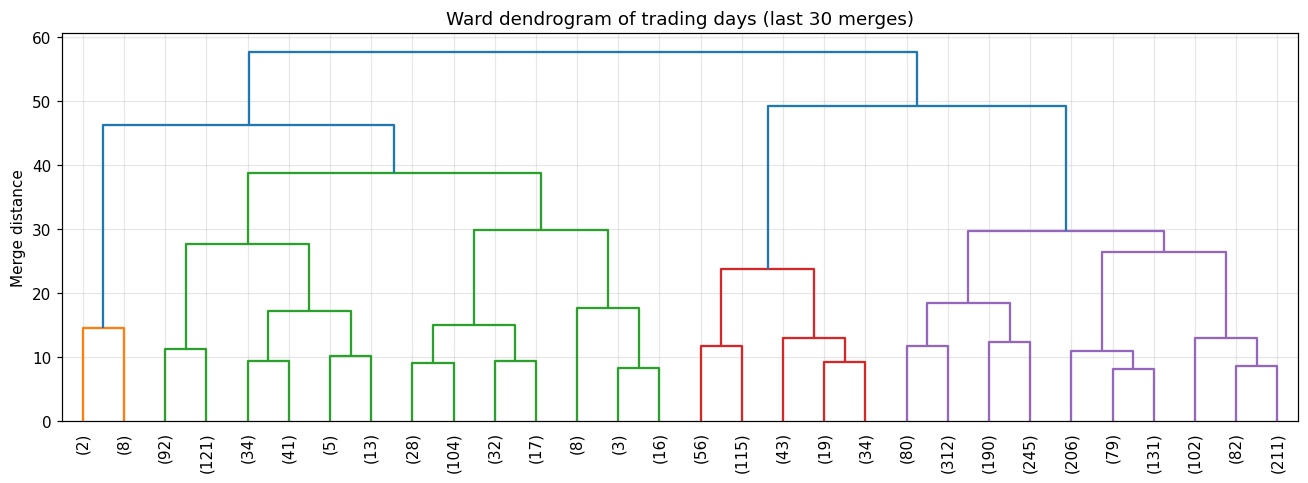

Cutting into 2 clusters leaves a vertical gap of 8.5
Cutting into 3 clusters leaves a vertical gap of 3.0
Cutting into 4 clusters leaves a vertical gap of 7.6
Cutting into 5 clusters leaves a vertical gap of 8.9
Cutting into 6 clusters leaves a vertical gap of 0.1
Cutting into 7 clusters leaves a vertical gap of 2.0
Cutting into 8 clusters leaves a vertical gap of 1.4
Cutting into 9 clusters leaves a vertical gap of 2.6


In [26]:
ward_tree = linkage(X, method='ward')

plt.figure(figsize=(12, 4.5))
dendrogram(ward_tree, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90)
plt.title('Ward dendrogram of trading days (last 30 merges)'); plt.ylabel('Merge distance')
plt.tight_layout(); savefig('D4_dendrogram.png'); plt.show()

final_heights = ward_tree[-10:, 2][::-1]          # heights of the last 10 merges, largest first
for n_clusters in range(2, 10):
    gap = final_heights[n_clusters - 2] - final_heights[n_clusters - 1]
    print(f'Cutting into {n_clusters} clusters leaves a vertical gap of {gap:.1f}')

**What the output shows.** The biggest vertical gaps are when cutting at **2 clusters (8.5)** and **5 clusters (8.9)**, then 4 clusters (7.6). The gap at 3 clusters is small (3.0). So the dendrogram by itself would suggest 2 clusters (or 5, but we already ruled out k ≥ 4 because of the tiny clusters).

#### Step 4.7
**Why this step?** The metrics point towards k = 2 or k = 3, so we look at *what* each algorithm separates at those two values before deciding. A useful clustering should be explainable, not just score well.

In [27]:
def mean_profile(labels):
    profile = cluster_data.groupby(labels)[FEATURES].mean()
    profile['n_days'] = np.bincount(labels)
    return profile.round(4)

for k in (2, 3):
    km_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    ward_labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    print(f'K-Means, k = {k}'); display(mean_profile(km_labels))
    print(f'Agglomerative (Ward), k = {k}'); display(mean_profile(ward_labels))

K-Means, k = 2


,log_return,intraday_range,volatility_20d,rel_volume_20d,n_days
0,-0.0006,0.0566,0.0415,0.2891,326
1,0.0002,0.0238,0.0174,-0.1635,2103


Agglomerative (Ward), k = 2


,log_return,intraday_range,volatility_20d,rel_volume_20d,n_days
0,-0.0005,0.0235,0.0201,-0.2768,1905
1,0.0022,0.0453,0.0228,0.5302,524


K-Means, k = 3


,log_return,intraday_range,volatility_20d,rel_volume_20d,n_days
0,0.0038,0.0319,0.0184,0.3490,862
1,-0.0015,0.0215,0.0180,-0.4044,1395
2,-0.0052,0.0642,0.0535,0.0803,172


Agglomerative (Ward), k = 3


,log_return,intraday_range,volatility_20d,rel_volume_20d,n_days
0,0.0022,0.0453,0.0228,0.5302,524
1,-0.0002,0.0225,0.0162,-0.2586,1638
2,-0.0022,0.0297,0.0437,-0.3888,267


**What the output shows.** **Decision: k = 3.** The evidence points in different directions, so this is a reasoned judgement:
- *For k = 2:* the best silhouette for both algorithms (K-Means 0.492, Ward 0.334) and the largest dendrogram gap.
- *For k = 3:* a better Davies–Bouldin Index for both algorithms (K-Means 1.453 → 1.392; Ward 1.688 → 1.481).
- **Interpretation tips the balance.** At k = 2 the two algorithms split the days on *different* things. K-Means separates 326 high-**volatility** days (volatility 0.0415). Ward separates 524 high-**volume** days (relative volume +0.53, intraday range 0.0453). At **k = 3 both algorithms capture both ideas** (a calm group, a busy group and a volatile group), which is more informative for our question and lets us compare the algorithms like for like.

We accept that k = 2 is also defensible. This is noted as a limitation.

#### Step 4.8
**Why this step?** We fit the final models with **k = 3**: K-Means and Agglomerative with Ward linkage. Cluster numbers are arbitrary (K-Means might call the calm group '2' in one run and '0' in another), so we renumber the clusters from the lowest to the highest average volatility. That makes the two algorithms easy to compare.

In [28]:
K_FINAL = 3

kmeans_labels = KMeans(n_clusters=K_FINAL, n_init=10, max_iter=300, random_state=RANDOM_STATE).fit_predict(X)
ward_labels = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit_predict(X)

def order_by_volatility(labels):
    order = cluster_data.groupby(labels)['volatility_20d'].mean().sort_values().index
    new_number = {old: new for new, old in enumerate(order)}
    return np.array([new_number[label] for label in labels])

kmeans_labels = order_by_volatility(kmeans_labels)
ward_labels = order_by_volatility(ward_labels)

clusters = cluster_data.copy()
clusters['KMeans'] = kmeans_labels
clusters['Ward'] = ward_labels
pd.DataFrame({'KMeans days': clusters['KMeans'].value_counts().sort_index(),
              'Ward days': clusters['Ward'].value_counts().sort_index()})

,KMeans days,Ward days
0,1395,1638
1,862,524
2,172,267


#### Step 4.9
**Why this step?** To interpret the clusters, we calculate the average of each feature per cluster in the **original units** (not the scaled ones), plus the average size of the daily move. That lets us describe each cluster in plain business terms.

In [29]:
def describe_clusters(column):
    summary = clusters.groupby(column)[FEATURES].mean()
    summary['mean_abs_return'] = clusters['log_return'].abs().groupby(clusters[column]).mean()
    summary['days'] = clusters.groupby(column).size()
    summary['% of days'] = summary['days'] / len(clusters) * 100
    return summary

print('K-Means clusters'); display(describe_clusters('KMeans'))
print('Ward clusters'); display(describe_clusters('Ward'))

K-Means clusters


,log_return,intraday_range,volatility_20d,rel_volume_20d,mean_abs_return,days,% of days
KMeans,,,,,,,
0,-0.0015,0.0215,0.0180,-0.4044,0.0102,1395,57.4310
1,0.0038,0.0319,0.0184,0.3490,0.0173,862,35.4879
2,-0.0052,0.0642,0.0535,0.0803,0.0442,172,7.0811


Ward clusters


,log_return,intraday_range,volatility_20d,rel_volume_20d,mean_abs_return,days,% of days
Ward,,,,,,,
0,-0.0002,0.0225,0.0162,-0.2586,0.0108,1638,67.4352
1,0.0022,0.0453,0.0228,0.5302,0.0293,524,21.5727
2,-0.0022,0.0297,0.0437,-0.3888,0.0141,267,10.9922


**What the output shows.** Clusters are numbered from lowest to highest average volatility. The **K-Means clusters** can be described as:

| Cluster | Days | What the averages show | Name we use |
|---|---|---|---|
| 0 | 1,395 (57.4%) | narrow range (2.15%), normal volatility (1.80%), volume about 33% *below* its recent average (−0.40), small moves (1.02%) | **Calm, quiet days** |
| 1 | 862 (35.5%) | wider range (3.19%), normal volatility (1.84%), volume about 42% *above* average (+0.35), moves of 1.73% | **Active, busy days** |
| 2 | 172 (7.1%) | very wide range (6.42%), volatility about three times higher (5.35%), moves of 4.42% | **High-volatility (stress) days** |

**Ward** finds a similar calm group (1,638 days) and a busy group (524 days, volume +0.53, range 4.53%). Its third group (267 days) is different: high recent volatility (4.37%) but *below-average* volume (−0.39) and moderate moves (1.41%). These are quieter days inside volatile periods.

Average daily returns per cluster are close to zero, so the clusters describe **how active and volatile** a day is, not whether the market went up or down. Labels like "bull" or "bear" market would not be justified.

#### Step 4.10
**Why this step?** Scatter plots of feature pairs show how the clusters sit in the data: whether they are clearly separated islands or parts of one continuous cloud.

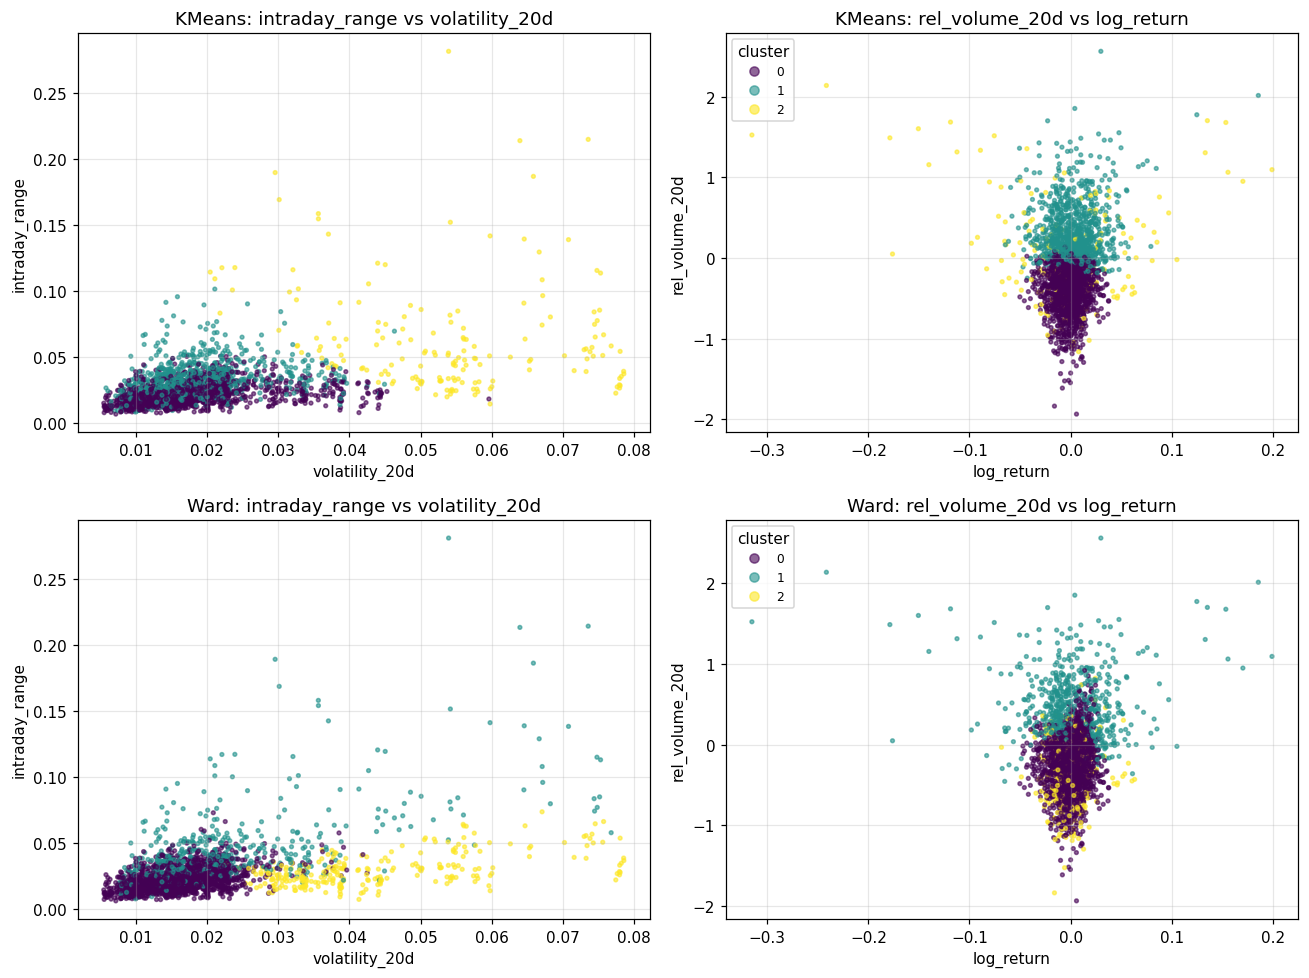

In [30]:
pairs = [('volatility_20d', 'intraday_range'), ('log_return', 'rel_volume_20d')]
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for row, algorithm in enumerate(['KMeans', 'Ward']):
    for col, (x_feat, y_feat) in enumerate(pairs):
        points = ax[row, col].scatter(clusters[x_feat], clusters[y_feat], c=clusters[algorithm], cmap='viridis', s=6, alpha=0.6)
        ax[row, col].set_xlabel(x_feat); ax[row, col].set_ylabel(y_feat)
        ax[row, col].set_title(f'{algorithm}: {y_feat} vs {x_feat}')
    ax[row, 1].legend(*points.legend_elements(), title='cluster', fontsize=8)
plt.tight_layout(); savefig('D7_cluster_scatter.png'); plt.show()

**What the output shows.** The clusters are **not separate islands**. They are regions of one continuous cloud of points.
- **K-Means** divides the cloud mainly by volatility (cluster 2 on the right of the left-hand plots) and by relative volume (cluster 1 above zero, cluster 0 below zero in the right-hand plots).
- **Ward** separates its third group along volatility, but with low volume.
- The colours overlap at the boundaries, which explains the modest silhouette scores.

#### Step 4.11
**Why this step?** The clustering didn't use dates at all. If the clusters still group together in time (for example, volatile days falling in particular periods), that suggests they capture real market conditions rather than random splits. We colour the price chart by cluster and count the share of each cluster per year.

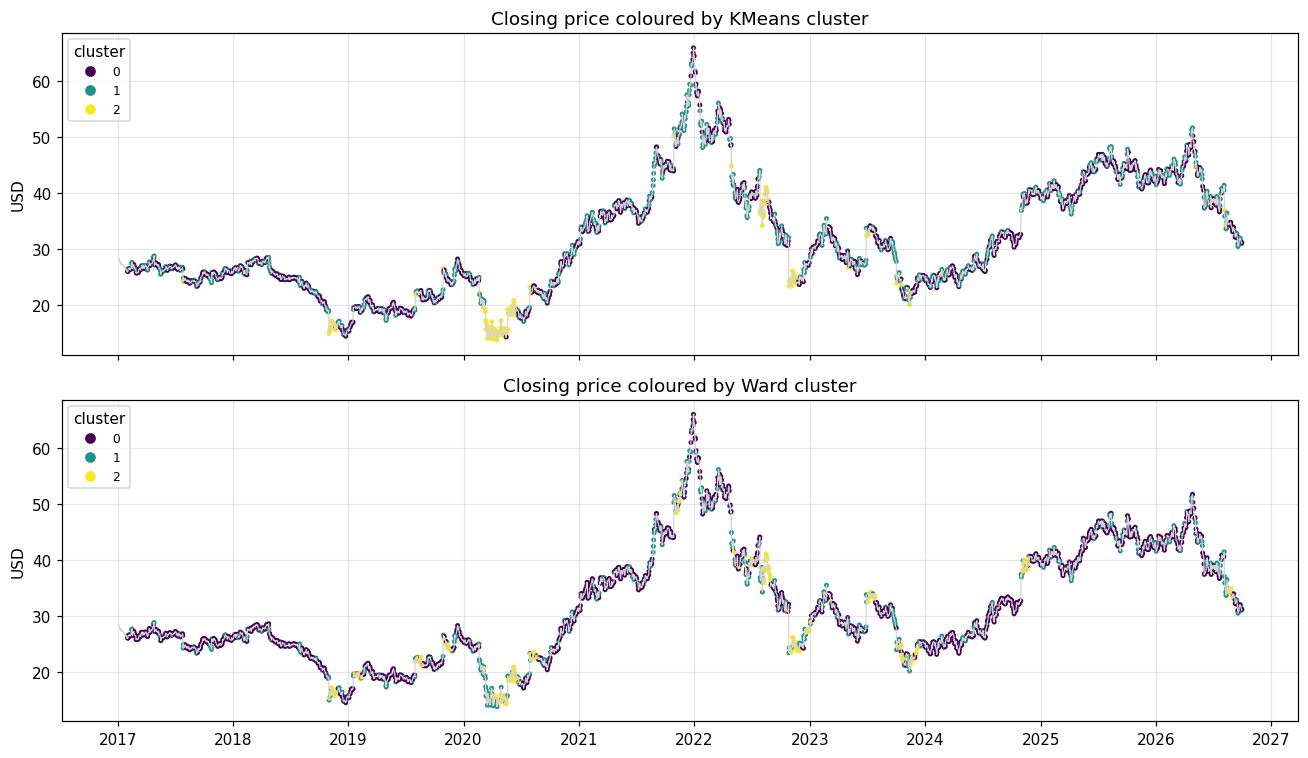

Share of days in each K-Means cluster per year (%)


KMeans,0,1,2
row_0,,,
2017,65.8000,33.8000,0.4000
2018,60.2000,32.3000,7.6000
2019,66.7000,31.7000,1.6000
2020,43.1000,25.7000,31.2000
2021,56.0000,43.7000,0.4000
2022,48.6000,34.3000,17.1000
2023,54.8000,38.0000,7.2000
2024,60.3000,38.5000,1.2000
2025,66.0000,34.0000,0.0000


In [31]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for i, algorithm in enumerate(['KMeans', 'Ward']):
    ax[i].plot(data.index, data['Close'], color='lightgrey', lw=0.8)
    points = ax[i].scatter(clusters.index, data.loc[clusters.index, 'Close'], c=clusters[algorithm], cmap='viridis', s=5)
    ax[i].set_title(f'Closing price coloured by {algorithm} cluster'); ax[i].set_ylabel('USD')
    ax[i].legend(*points.legend_elements(), title='cluster', loc='upper left', fontsize=8)
plt.tight_layout(); savefig('D8_clusters_time.png'); plt.show()

print('Share of days in each K-Means cluster per year (%)')
(pd.crosstab(clusters.index.year, clusters['KMeans'], normalize='index') * 100).round(1)

**What the output shows.** Even though the algorithm never saw the dates, **high-volatility days (K-Means cluster 2) bunch together in time**: 31.2% of days in 2020, 17.1% in 2022, 7.6% in 2018 and 7.2% in 2023, but 0.0% in 2025. On the chart they line up with the sharp price falls of late 2018, the first half of 2020, 2022 and late 2023. This suggests the clusters reflect real, recurring market conditions. (The 2020 cluster may relate to the general market turbulence that year, but that is outside context and was not tested here.)

#### Step 4.12
**Why this step?** Now we compare the two final solutions on the two metrics required by the brief, plus the cluster sizes.

In [32]:
comparison = pd.DataFrame({
    'silhouette': [silhouette_score(X, kmeans_labels), silhouette_score(X, ward_labels)],
    'davies_bouldin': [davies_bouldin_score(X, kmeans_labels), davies_bouldin_score(X, ward_labels)],
    'smallest_cluster_%': [np.bincount(kmeans_labels).min() / len(X) * 100, np.bincount(ward_labels).min() / len(X) * 100],
    'largest_cluster_%': [np.bincount(kmeans_labels).max() / len(X) * 100, np.bincount(ward_labels).max() / len(X) * 100],
}, index=['K-Means (k=3)', 'Agglomerative Ward (k=3)'])
comparison

,silhouette,davies_bouldin,smallest_cluster_%,largest_cluster_%
K-Means (k=3),0.2571,1.3923,7.0811,57.4310
Agglomerative Ward (k=3),0.3124,1.4807,10.9922,67.4352


#### Step 4.13
**Why this step?** The metrics don't tell us whether the two algorithms found the *same* groups. A cross-tabulation shows which K-Means cluster each Ward cluster's days fall into, and the **Adjusted Rand Index** (ARI) summarises the agreement: 1 means identical, about 0 means no better than chance.

In [33]:
print(f'Agreement between K-Means and Ward (ARI): {adjusted_rand_score(kmeans_labels, ward_labels):.3f}')
pd.crosstab(pd.Series(kmeans_labels, name='K-Means'), pd.Series(ward_labels, name='Ward'))

Agreement between K-Means and Ward (ARI): 0.380


Ward,0,1,2
K-Means,,,
0,1254,1,140
1,380,454,28
2,4,69,99


#### Step 4.14
**Why this step?** A useful segmentation should not change a lot when the data changes slightly. We test **stability** in two ways:
1. K-Means with 10 different random seeds.
2. Both algorithms refitted on random 80% samples of the days (5 repeats), comparing the new labels with the original ones using ARI.

In [34]:
seed_agreement = [adjusted_rand_score(kmeans_labels,
                                      KMeans(n_clusters=K_FINAL, n_init=10, random_state=seed).fit_predict(X))
                  for seed in range(10)]
print(f'K-Means across 10 seeds: mean ARI {np.mean(seed_agreement):.3f} (lowest {np.min(seed_agreement):.3f})')

rng = np.random.default_rng(RANDOM_STATE)
kmeans_subsample, ward_subsample = [], []
for repeat in range(5):
    sample = np.sort(rng.choice(len(X), size=int(0.8 * len(X)), replace=False))
    kmeans_subsample.append(adjusted_rand_score(kmeans_labels[sample],
                            KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit_predict(X[sample])))
    ward_subsample.append(adjusted_rand_score(ward_labels[sample],
                          AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit_predict(X[sample])))
print(f'80% subsamples: K-Means mean ARI {np.mean(kmeans_subsample):.3f} | Ward mean ARI {np.mean(ward_subsample):.3f}')

K-Means across 10 seeds: mean ARI 0.946 (lowest 0.901)


80% subsamples: K-Means mean ARI 0.877 | Ward mean ARI 0.476


**What the output shows.** **Comparison of the final solutions:**

| | K-Means | Ward | Better |
|---|---|---|---|
| Silhouette (higher is better) | 0.257 | **0.312** | Ward |
| Davies–Bouldin (lower is better) | **1.392** | 1.481 | K-Means |
| Smallest / largest cluster | 7.1% / 57.4% | 11.0% / 67.4% | both acceptable |
| Agreement between the two (ARI) | 0.380 | | moderate |
| Stability across 10 seeds (ARI) | 0.946 | (deterministic) | |
| Stability on 80% samples (ARI) | **0.877** | 0.476 | K-Means |

- The two metrics **disagree**, and both silhouette values are fairly low. That fits the scatter plots: the structure is real but weak.
- The algorithms agree strongly on the calm group (1,254 days in common) but split the busy and volatile days differently.
- **Ward is much less stable**: removing 20% of the days changes its clusters a lot (ARI 0.476). Once two clusters are merged, the merge can't be undone, so small changes in the data spread up the tree. K-Means gives nearly the same answer every time.

### Preferred clustering solution

**Preferred solution: K-Means with k = 3.** Reasons:
1. Better Davies–Bouldin Index (1.392 vs 1.481).
2. Much more stable when the data changes (ARI 0.877 vs 0.476), so the segments can be trusted more.
3. Each cluster is easy to explain: quiet, busy or volatile.
4. Every cluster is big enough to be useful (at least 7% of days).
5. It is quicker to compute and to explain.

**Trade-off:** Ward has the higher silhouette score (0.312 vs 0.257). We present the result honestly as a **weakly separated segmentation**.

**About the metrics:**
- Silhouette looks at every single point, but it favours round, evenly spread clusters, and it can be "fooled" by splitting off outliers (as with single linkage).
- Davies–Bouldin is quick and based on centroids, but it uses only the *worst* neighbouring cluster for each cluster, and it also rewards isolating outliers.
- Neither metric can tell us whether clusters are *useful*. That is why we also used cluster sizes, stability, timing and interpretation.

---
## 5. Time-series analysis and forecasting (Part 3)

**Target:** the daily **Close** price in USD.
- **Why Close and not Adj Close?** Close is the price that actually traded and it never changes afterwards. Adj Close is recalculated every time a new dividend is paid, so its history depends on when you download it.
- Close is also the variable used in the module's stock example (DJIA `Close`, Tutorial 6(a)).
- **Small drawback:** on the 39 ex-dividend days Close drops by the dividend (0.05–0.113 USD) for a purely technical reason.

**Approach:** the Box–Jenkins steps from Lecture 5 (p. 12) and the ARIMA steps from Lecture 6 (p. 7): check stationarity → difference → hold out a validation sample → choose AR and MA terms from ACF/PACF (and AIC) → build the model → validate it against the held-out data.

#### Step 5.1
**Why this step?** We split the series **in time order**, never randomly, so the model is always tested on the future relative to what it learned from. The last **126 trading days** (about six months, April–September 2026) are the test set. Everything before that is training data and is used for all exploration, order selection and parameter estimation.

Training: 2323 days, 2017-01-03 to 2026-03-31
Test    : 126 days, 2026-04-01 to 2026-09-30
Last training close 45.66 | test: first 45.47, max 51.65, min 30.48, last 31.17


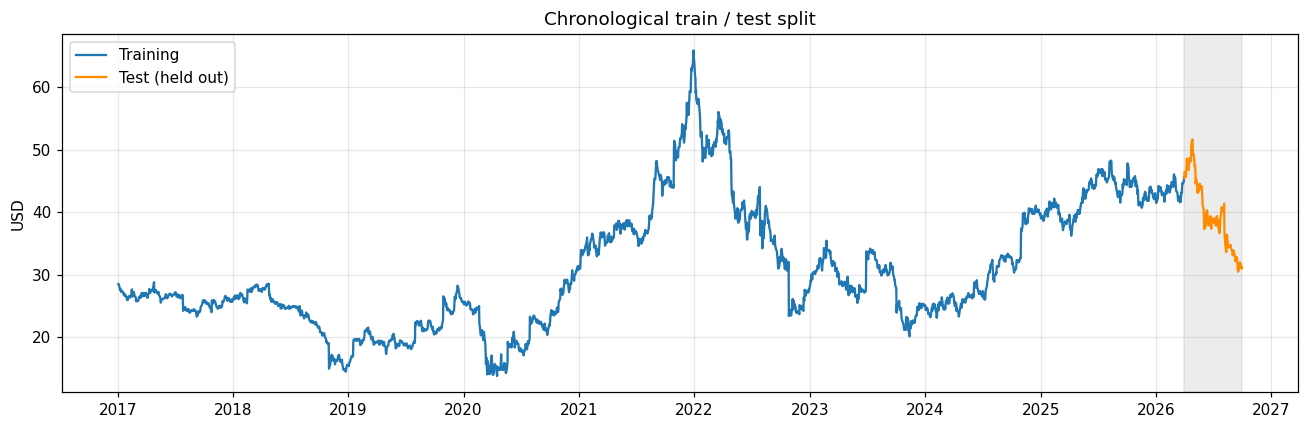

In [35]:
close = data['Close']
TEST_DAYS = 126                              # about six months of trading days
train, test = close.iloc[:-TEST_DAYS], close.iloc[-TEST_DAYS:]

print(f'Training: {len(train)} days, {train.index.min().date()} to {train.index.max().date()}')
print(f'Test    : {len(test)} days, {test.index.min().date()} to {test.index.max().date()}')
print(f'Last training close {train.iloc[-1]:.2f} | test: first {test.iloc[0]:.2f}, '
      f'max {test.max():.2f}, min {test.min():.2f}, last {test.iloc[-1]:.2f}')

plt.figure(figsize=(12, 4))
plt.plot(train, label='Training'); plt.plot(test, color='darkorange', label='Test (held out)')
plt.axvspan(test.index.min(), test.index.max(), color='grey', alpha=0.15)
plt.title('Chronological train / test split'); plt.ylabel('USD'); plt.legend()
plt.tight_layout(); savefig('E2_split.png'); plt.show()

**What the output shows.** The model learns from **2,323 days** (Jan 2017 – Mar 2026) and is tested on **126 days** (Apr – Sep 2026). The test period was difficult: the price went from 45.47 up to 51.65 and then fell to 30.48 before ending at 31.17. A drop of that size is a real challenge for any forecasting model.

#### Step 5.2
**Why this step?** Lecture 5 (p. 7) defines a stationary series as one whose mean and variance don't change over time. A first, informal check is to plot a rolling mean and rolling standard deviation (as in Tutorial 5(a)) and compare the two halves of the training data.

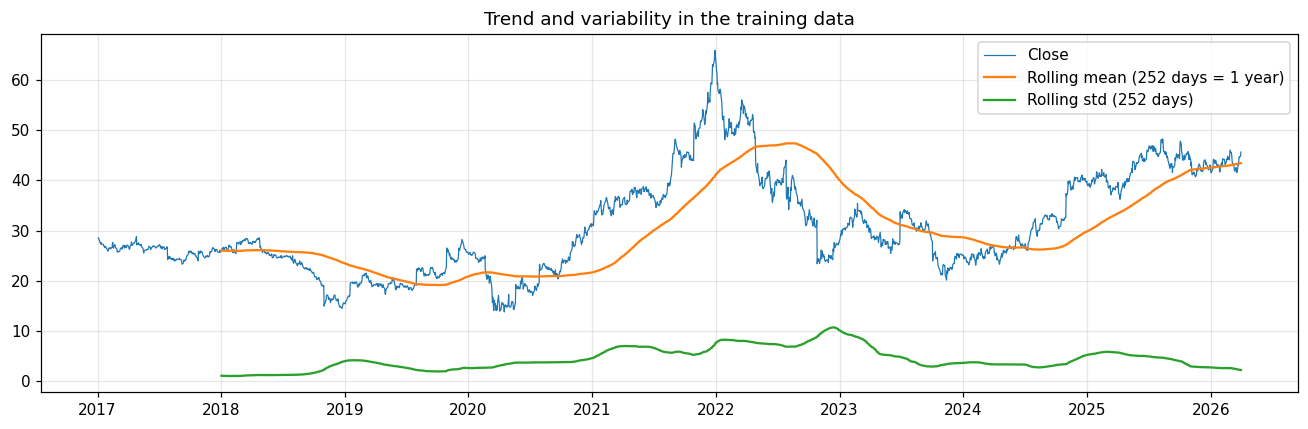

First half : mean 24.76, variance 33.19
Second half: mean 36.88, variance 85.21


In [36]:
plt.figure(figsize=(12, 4))
plt.plot(train, lw=0.8, label='Close')
plt.plot(train.rolling(252).mean(), lw=1.5, label='Rolling mean (252 days = 1 year)')
plt.plot(train.rolling(252).std(), lw=1.5, label='Rolling std (252 days)')
plt.title('Trend and variability in the training data'); plt.legend()
plt.tight_layout(); savefig('E3_rolling.png'); plt.show()

half = len(train) // 2
print(f'First half : mean {train.iloc[:half].mean():.2f}, variance {train.iloc[:half].var():.2f}')
print(f'Second half: mean {train.iloc[half:].mean():.2f}, variance {train.iloc[half:].var():.2f}')

**What the output shows.** The rolling mean moves up and down with the price, and the rolling standard deviation is not constant. The second half of the training data has a much higher mean (36.88 vs 24.76) and more than double the variance (85.21 vs 33.19). Both point to a **non-stationary** series.

#### Step 5.3
**Why this step?** The formal test is the **Augmented Dickey–Fuller (ADF)** test (Lecture 5, pp. 8–9):
- H₀: the series has a unit root, i.e. it is **not stationary**.
- If p ≤ 0.05 we reject H₀ and treat the series as stationary.

We test the price level, then the first difference and the second difference. The number of differences needed to become stationary gives **d**.

Close (level)            ADF =   -1.383   p = 0.5904   -> NOT stationary
Close (1st difference)   ADF =  -49.476   p = 0.0000   -> stationary


Close (2nd difference)   ADF =  -15.599   p = 0.0000   -> stationary


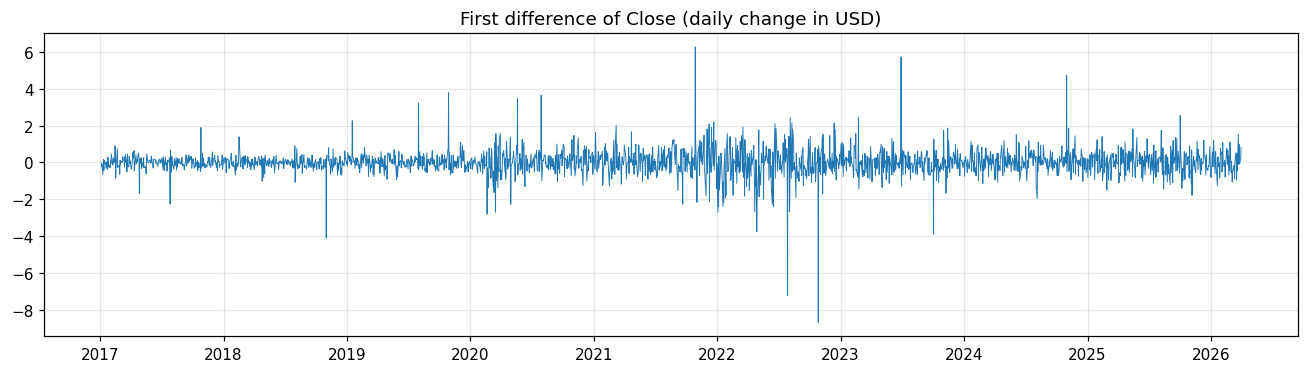

In [37]:
def adf_test(series, name):
    statistic, p_value = adfuller(series.dropna(), autolag='AIC')[:2]
    verdict = 'stationary' if p_value <= 0.05 else 'NOT stationary'
    print(f'{name:<24} ADF = {statistic:8.3f}   p = {p_value:.4f}   -> {verdict}')

adf_test(train, 'Close (level)')
adf_test(train.diff(), 'Close (1st difference)')
adf_test(train.diff().diff(), 'Close (2nd difference)')

plt.figure(figsize=(12, 3.5))
plt.plot(train.diff(), lw=0.6); plt.title('First difference of Close (daily change in USD)')
plt.tight_layout(); savefig('E4_diff.png'); plt.show()

**What the output shows.** - **Price level:** ADF = −1.383, p = 0.590 > 0.05. We cannot reject H₀, so the price is **not stationary**.
- **After one difference:** ADF = −49.48, p < 0.0001. The daily changes **are stationary**.
- Differencing a second time isn't needed and would over-difference the series.

**So d = 1.** The chart of daily changes moves around zero, with bigger swings in the volatile periods.

#### Step 5.4
**Why this step?** The ACF and PACF of the differenced series help choose **p** (AR order) and **q** (MA order). As taught in Lecture 6 and Tutorial 6(a), a sharp cut-off in the PACF suggests the AR order and a cut-off in the ACF suggests the MA order. We also print which lags fall outside the 95% bands, so the reading isn't based only on eyeballing the plot.

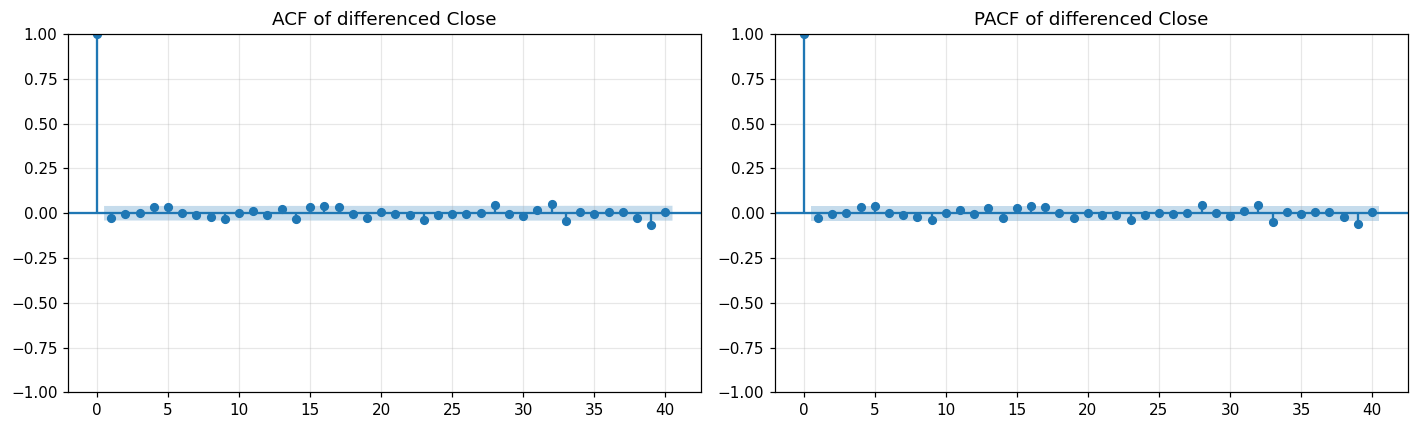

95% band: +/-0.041
Significant ACF lags : [28, 32, 33, 39]
Significant PACF lags: [28, 32, 33, 39]
ACF lags 1-5 : [-0.027 -0.003  0.002  0.035  0.036]
PACF lags 1-5: [-0.027 -0.004  0.002  0.035  0.038]


In [38]:
daily_change = train.diff().dropna()
LAGS = 40

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(daily_change, lags=LAGS, ax=ax[0]); ax[0].set_title('ACF of differenced Close')
plot_pacf(daily_change, lags=LAGS, ax=ax[1], method='ywm'); ax[1].set_title('PACF of differenced Close')
plt.tight_layout(); savefig('E5_acf_pacf.png'); plt.show()

band = 1.96 / np.sqrt(len(daily_change))
acf_values = acf(daily_change, nlags=LAGS)
pacf_values = pacf(daily_change, nlags=LAGS, method='ywm')
print(f'95% band: +/-{band:.3f}')
print('Significant ACF lags :', [lag for lag in range(1, LAGS + 1) if abs(acf_values[lag]) > band])
print('Significant PACF lags:', [lag for lag in range(1, LAGS + 1) if abs(pacf_values[lag]) > band])
print('ACF lags 1-5 :', acf_values[1:6].round(3))
print('PACF lags 1-5:', pacf_values[1:6].round(3))

**What the output shows.** The ACF and PACF are **almost flat**. All values at lags 1–5 are inside the ±0.041 band (lag 1 is only −0.027), and nothing is significant until lag 28. The few significant lags (28, 32, 33 and 39) are isolated and small. With 40 lags tested at the 5% level, about 2 would cross the band by chance anyway.

There is no clear cut-off, which suggests **p = 0 and q = 0**: today's price change says almost nothing about tomorrow's. We confirm this with an AIC search in step 5.7.

#### Step 5.5
**Why this step?** Before considering a SARIMA model, we need **evidence** of seasonality, rather than assuming daily stock prices have it. Lecture 6 (pp. 9–10) identifies seasonal terms from spikes at the seasonal lags of the ACF/PACF. Trading data has no obvious season, so we check the most plausible candidates: weekly (5 trading days), monthly (21), quarterly (63), half-yearly (126) and yearly (252).

weekly     lag   5: ACF = +0.036   significant: False
two weeks  lag  10: ACF = +0.003   significant: False
monthly    lag  21: ACF = -0.007   significant: False
quarterly  lag  63: ACF = +0.024   significant: False
half-year  lag 126: ACF = -0.009   significant: False
yearly     lag 252: ACF = +0.035   significant: False


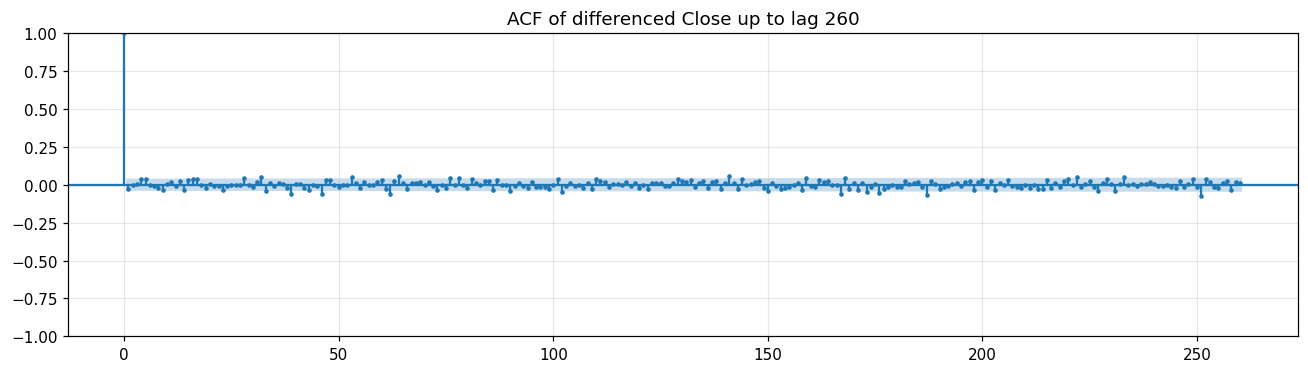

In [39]:
long_acf = acf(daily_change, nlags=260)
candidate_lags = {'weekly': 5, 'two weeks': 10, 'monthly': 21, 'quarterly': 63, 'half-year': 126, 'yearly': 252}
for name, lag in candidate_lags.items():
    print(f'{name:<10} lag {lag:>3}: ACF = {long_acf[lag]:+.3f}   significant: {abs(long_acf[lag]) > band}')

fig, ax = plt.subplots(figsize=(12, 3.5))
plot_acf(daily_change, lags=260, ax=ax, markersize=2)
ax.set_title('ACF of differenced Close up to lag 260')
plt.tight_layout(); savefig('E6_acf_long.png'); plt.show()

**What the output shows.** **None of the seasonal lags is significant** (weekly, monthly, quarterly, half-yearly or yearly), and the long ACF plot shows no repeating spikes. There is no evidence of seasonality.

#### Step 5.6
**Why this step?** As a second check we use the classical decomposition from Tutorial 5(a) (`seasonal_decompose`) with a one-year period of 252 trading days, and compare the size of the 'seasonal' part with the leftover residual. Note that this method *always* produces a seasonal component, so it can't prove seasonality on its own.

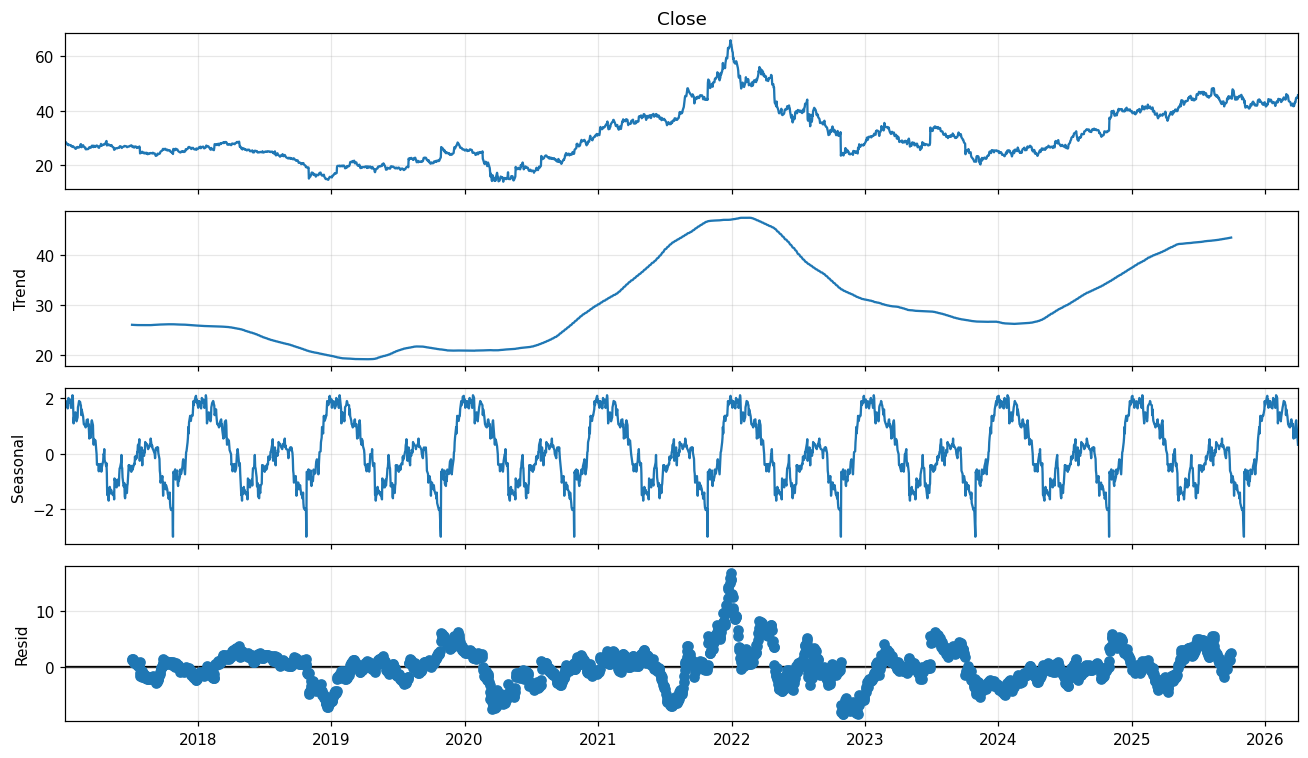

Std of seasonal component: 1.101 USD
Std of residual component: 3.117 USD


In [40]:
decomposition = seasonal_decompose(train, model='additive', period=252)
fig = decomposition.plot(); fig.set_size_inches(12, 7)
plt.tight_layout(); savefig('E6_decomposition.png'); plt.show()
print(f'Std of seasonal component: {decomposition.seasonal.std():.3f} USD')
print(f'Std of residual component: {decomposition.resid.std():.3f} USD')

**What the output shows.** The decomposition produces a "seasonal" pattern with a standard deviation of 1.10 USD, much smaller than the residual (3.12 USD). Remember that this method creates a seasonal component whatever period it is given, and the ACF in the previous step found nothing at the seasonal lags. **Conclusion: SARIMA is not justified**, so we don't fit a seasonal model. Forcing one in would add parameters for a pattern that isn't in the data.

#### Step 5.7
**Why this step?** The ACF/PACF give only a rough idea of p and q. Following Lecture 5 (p. 20) and Tutorial 6(a), we fit every ARIMA(p, 1, q) with p and q from 0 to 3 **on the training data only**, and compare the **AIC** (lower is better). We also show the BIC, which penalises extra parameters more heavily, and whether each model's estimation converged. A grid of 0–3 is wide enough given that the ACF/PACF showed almost nothing at short lags.

In [41]:
train_values = train.reset_index(drop=True)      # plain 0..n index: trading days have no regular frequency
order_search = []
for p in range(4):
    for q in range(4):
        with warnings.catch_warnings():          # silence optimiser start-up messages from statsmodels
            warnings.simplefilter('ignore')
            fitted = ARIMA(train_values, order=(p, 1, q)).fit()
        order_search.append({'p': p, 'd': 1, 'q': q, 'AIC': fitted.aic, 'BIC': fitted.bic,
                             'converged': fitted.mle_retvals.get('converged')})
order_search = pd.DataFrame(order_search).sort_values('AIC').reset_index(drop=True)
display(order_search.head(8))

best_aic = order_search.iloc[0]
best_bic = order_search.sort_values('BIC').iloc[0]
print(f'Lowest AIC: ARIMA({best_aic.p}, 1, {best_aic.q})  AIC = {best_aic.AIC:.2f}')
print(f'Lowest BIC: ARIMA({best_bic.p}, 1, {best_bic.q})  BIC = {best_bic.BIC:.2f}')

,p,d,q,AIC,BIC,converged
0,2,1,2,"4,900.2846","4,929.0356",True
1,2,1,3,"4,901.3958","4,935.8969",True
2,3,1,2,"4,901.5075","4,936.0086",False
3,0,1,0,"4,903.5201","4,909.2703",True
4,0,1,1,"4,903.7882","4,915.2886",True
5,1,1,0,"4,903.7991","4,915.2995",True
6,3,1,3,"4,904.0341","4,944.2854",True
7,2,1,0,"4,905.7687","4,923.0193",True


Lowest AIC: ARIMA(2, 1, 2)  AIC = 4900.28
Lowest BIC: ARIMA(0, 1, 0)  BIC = 4909.27


**What the output shows.** - **ARIMA(2,1,2)** has the lowest AIC (4,900.28).
- **ARIMA(0,1,0)** has the lowest BIC (4,909.27).
- The AIC difference between them is only 3.24, and ARIMA(3,1,2) did not converge, so we ignore it.

The course selects the model with the minimum AIC (Lecture 5, p. 20; Tutorial 6(a)). The same slide also prefers a simpler model when the AIC difference is small. We therefore keep **ARIMA(2,1,2) as the main model** and **ARIMA(0,1,0) as the simple alternative**, which also matches what the ACF/PACF showed. ARIMA(0,1,0) is a *random walk*: its forecast for tomorrow is simply today's price.

#### Step 5.8
**Why this step?** We fit both candidate models on the training data: **ARIMA(2,1,2)** (lowest AIC) and **ARIMA(0,1,0)** (lowest BIC, a 'random walk'). The summary table shows the estimated coefficients and some built-in diagnostic tests.

In [42]:
ORDER_MAIN = (2, 1, 2)
ORDER_SIMPLE = (0, 1, 0)

with warnings.catch_warnings():                  # silence optimiser start-up messages
    warnings.simplefilter('ignore')
    main_model = ARIMA(train_values, order=ORDER_MAIN).fit()
    simple_model = ARIMA(train_values, order=ORDER_SIMPLE).fit()

print(main_model.summary())
print(f'\nARIMA{ORDER_SIMPLE}: AIC {simple_model.aic:.2f}, BIC {simple_model.bic:.2f}, sigma2 {simple_model.params["sigma2"]:.4f}')

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 2323
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -2445.142
Date:                Wed, 21 Oct 2026   AIC                           4900.285
Time:                        01:51:11   BIC                           4929.036
Sample:                             0   HQIC                          4910.762
                               - 2323                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5576      0.071     22.091      0.000       1.419       1.696
ar.L2         -0.8450      0.070    -12.068      0.000      -0.982      -0.708
ma.L1         -1.5785      0.064    -24.746      0.0

**What the output shows.** In ARIMA(2,1,2) all four coefficients are statistically significant, but look at their values. The AR terms (1.558, −0.845) and the MA terms (−1.579, 0.879) are **almost mirror images**, so they largely cancel each other out. The model therefore behaves very much like a random walk. Its error variance (σ² = 0.481) is barely smaller than the random walk's (0.483).

#### Step 5.9
**Why this step?** A good model should leave residuals that look like random noise. We use the diagnostic plots from Tutorial 6(b) (residuals over time, histogram, Q-Q plot, correlogram), plus the **Ljung–Box test** (extension), where H₀ is that there is no autocorrelation left in the residuals.

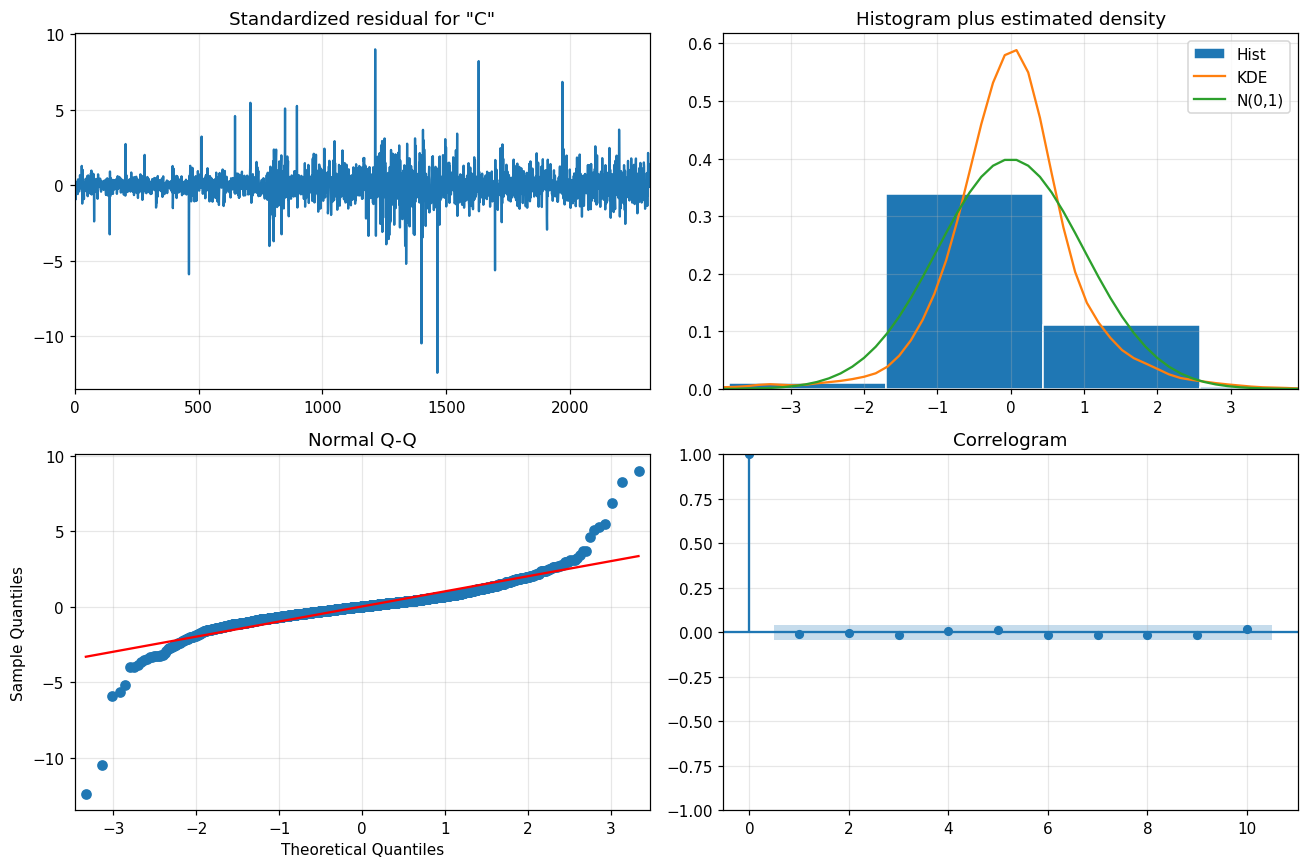

ARIMA(2, 1, 2)


,lb_stat,lb_pvalue
5,1.2961,0.9353
10,4.3939,0.9278
20,17.6191,0.6125


ARIMA(0, 1, 0)


,lb_stat,lb_pvalue
5,7.6859,0.1744
10,11.1630,0.3450
20,26.6916,0.1442


In [43]:
main_model.plot_diagnostics(figsize=(12, 8))
plt.tight_layout(); savefig('E8_diagnostics.png'); plt.show()

for name, model in [(f'ARIMA{ORDER_MAIN}', main_model), (f'ARIMA{ORDER_SIMPLE}', simple_model)]:
    print(name)
    display(acorr_ljungbox(model.resid.iloc[1:], lags=[5, 10, 20], return_df=True))   # skip the first residual (start-up value)

**What the output shows.** - **No autocorrelation left:** Ljung–Box p-values are 0.94, 0.93 and 0.61 (lags 5, 10, 20), and the correlogram stays inside the bands. The model has captured the (very small) linear pattern.
- **Not normal:** the Q-Q plot bends away at both ends, and Jarque–Bera = 54,230 (p ≈ 0) with kurtosis 26.6. There are many more extreme days than a normal distribution allows.
- **Variance not constant:** the heteroskedasticity test gives H = 2.47 (p ≈ 0), and the residual plot shows bigger swings in some periods.

The last two points mean the model's **prediction intervals are not reliable**: too wide in calm periods and too narrow in volatile ones. This is the same changing volatility that the clustering found.

#### Step 5.10
**Why this step?** Now the real test: forecasting the 126 days the models have **never seen**. We look at two situations:
1. **Multi-step forecast:** forecast all six months in one go from the end of the training data (as in Tutorial 6(b)).
2. **Rolling one-step forecast:** each morning, forecast that day's close using all prices up to yesterday (similar to the rolling forecast in Tutorial 5(c)). The coefficients stay fixed at the values learned from the training data, so no test data is used for fitting.

Both are compared with **baselines** from Tutorial 5(b): the *naïve* forecast (tomorrow = today; or, for multi-step, every future day = the last training price) and the *historical mean* of the training data. Metrics are MAE and RMSE in USD, plus MAPE in %. MAPE is fine here because prices are always well above zero.

In [44]:
def forecast_errors(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'MAPE %': np.mean(np.abs((actual - predicted) / actual)) * 100}

def rolling_one_step(fitted_model, order):
    # apply the training coefficients to the full series; prediction for day t only uses data up to t-1
    full_series = ARIMA(close.reset_index(drop=True), order=order).filter(fitted_model.params)
    prediction = full_series.get_prediction(start=len(train), end=len(close) - 1).predicted_mean
    return pd.Series(prediction.values, index=test.index)

multi_step = main_model.get_forecast(steps=TEST_DAYS)
multi_main = pd.Series(multi_step.predicted_mean.values, index=test.index)
interval_95 = pd.DataFrame(multi_step.conf_int(alpha=0.05).values, index=test.index, columns=['lower', 'upper'])
multi_simple = pd.Series(simple_model.get_forecast(steps=TEST_DAYS).predicted_mean.values, index=test.index)
one_step_main = rolling_one_step(main_model, ORDER_MAIN)
one_step_simple = rolling_one_step(simple_model, ORDER_SIMPLE)

naive_multi = pd.Series(train.iloc[-1], index=test.index)
mean_multi = pd.Series(train.mean(), index=test.index)
naive_one_step = close.shift(1).loc[test.index]

results = pd.DataFrame({
    'ARIMA(2,1,2) multi-step': forecast_errors(test, multi_main),
    'ARIMA(0,1,0) multi-step': forecast_errors(test, multi_simple),
    'Naive multi-step (last training price)': forecast_errors(test, naive_multi),
    'Historical mean': forecast_errors(test, mean_multi),
    'ARIMA(2,1,2) one-step': forecast_errors(test, one_step_main),
    'ARIMA(0,1,0) one-step': forecast_errors(test, one_step_simple),
    'Naive one-step (yesterday)': forecast_errors(test, naive_one_step),
}).T
display(results)
coverage = ((test >= interval_95['lower']) & (test <= interval_95['upper'])).mean()
print(f'Test days inside the 95% multi-step interval: {coverage:.1%}')

,MAE,RMSE,MAPE %
"ARIMA(2,1,2) multi-step",7.1265,8.3041,19.8017
"ARIMA(0,1,0) multi-step",7.0777,8.2458,19.6607
Naive multi-step (last training price),7.0777,8.2458,19.6607
Historical mean,8.7754,10.3950,20.6337
"ARIMA(2,1,2) one-step",0.6838,0.9102,1.7279
"ARIMA(0,1,0) one-step",0.6791,0.9072,1.7165
Naive one-step (yesterday),0.6791,0.9072,1.7165


Test days inside the 95% multi-step interval: 100.0%


#### Step 5.11
**Why this step?** Charts of actual against forecast values show *how* the forecasts fail or succeed, which the error numbers alone can't show.

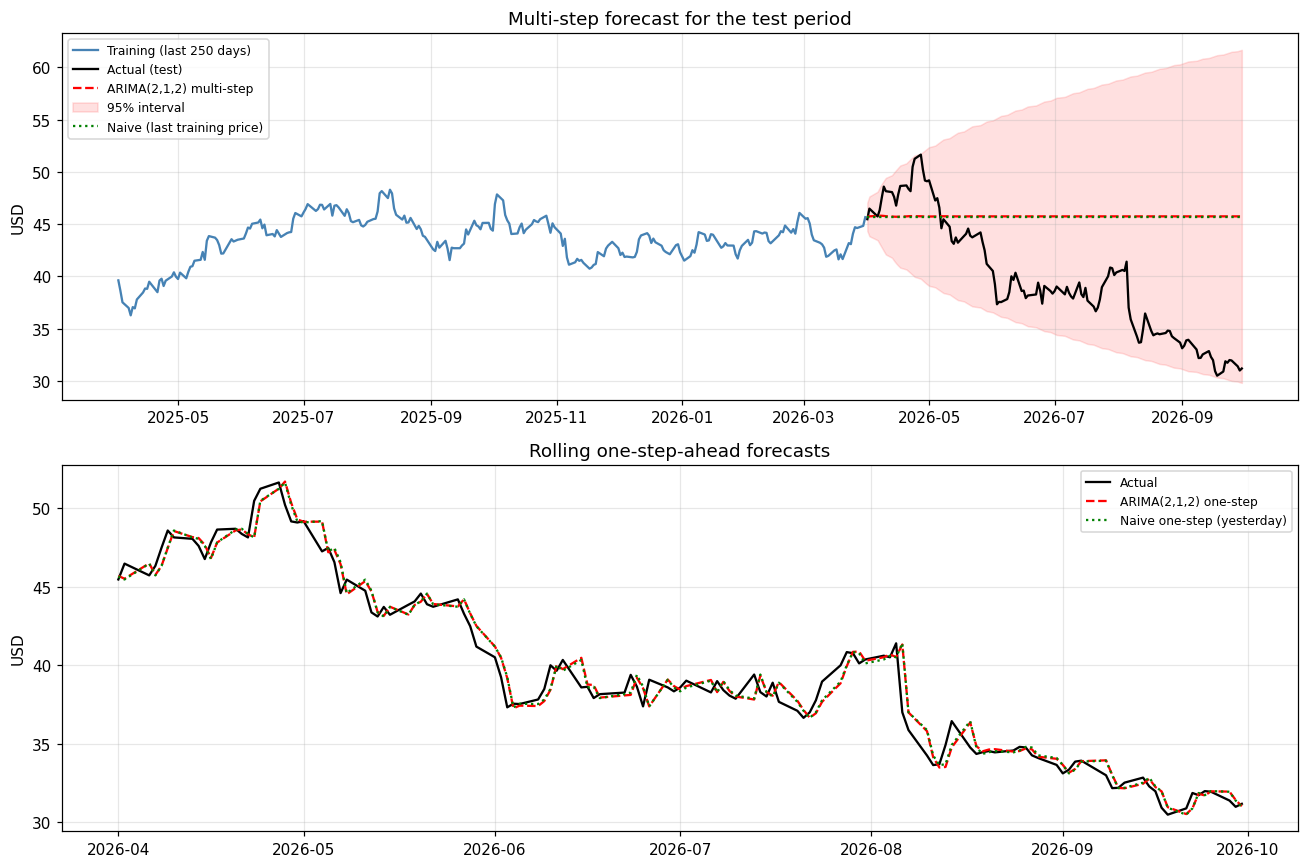

In [45]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
recent = train.iloc[-250:]
ax[0].plot(recent, color='steelblue', label='Training (last 250 days)')
ax[0].plot(test, color='black', label='Actual (test)')
ax[0].plot(multi_main, '--', color='red', label='ARIMA(2,1,2) multi-step')
ax[0].fill_between(test.index, interval_95['lower'], interval_95['upper'], color='red', alpha=0.12, label='95% interval')
ax[0].plot(naive_multi, ':', color='green', label='Naive (last training price)')
ax[0].set_title('Multi-step forecast for the test period'); ax[0].set_ylabel('USD'); ax[0].legend(fontsize=8)

ax[1].plot(test, color='black', label='Actual')
ax[1].plot(one_step_main, '--', color='red', label='ARIMA(2,1,2) one-step')
ax[1].plot(naive_one_step, ':', color='green', label='Naive one-step (yesterday)')
ax[1].set_title('Rolling one-step-ahead forecasts'); ax[1].set_ylabel('USD'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('E10_forecasts.png'); plt.show()

**What the output shows.** **Multi-step (top chart):**
- ARIMA(2,1,2) gives MAE 7.13 USD, RMSE 8.30 and MAPE 19.8%. That is **slightly worse than the naïve forecast** (MAE 7.08, RMSE 8.25, MAPE 19.7%), though better than the historical mean (MAE 8.78).
- The forecast is a nearly flat line at the last training price, so it has **no way of anticipating the fall** from May to September.
- The 95% interval contained every test day, but only because it is extremely wide (about 30 to 62 USD by the end). It is uninformative rather than accurate.

**Rolling one-step (bottom chart):**
- ARIMA(2,1,2) gives MAE 0.684 USD, RMSE 0.910 and MAPE 1.73%, again **marginally worse than "tomorrow = today"** (MAE 0.679, RMSE 0.907, MAPE 1.72%).
- The error looks small only because prices rarely move far in one day. The red line simply follows the black line one day late.
- ARIMA(0,1,0) produces exactly the naïve forecasts, as expected.

#### Step 5.12
**Why this step?** We check the **out-of-sample** errors of the one-step forecasts: are they biased (on average too high or too low) and do they still contain a pattern? We also compare the in-sample error (training) with the out-of-sample error (test), because a model always looks better on data it was fitted to.

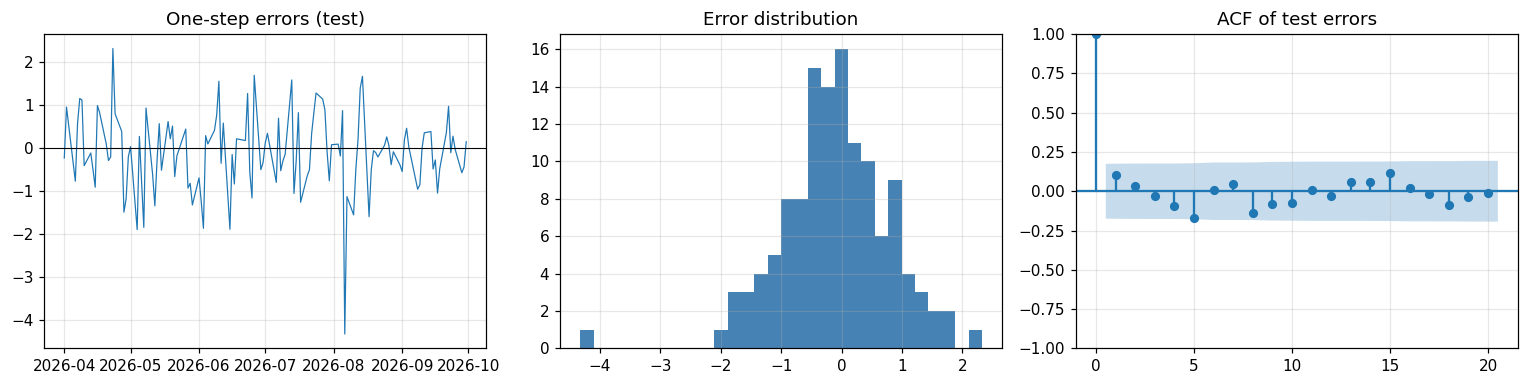

Mean error (bias): -0.111 USD | Std of errors: 0.907 USD


,lb_stat,lb_pvalue
5,6.5645,0.2551
10,11.1472,0.3462


In-sample one-step MAE (training): 0.444 USD
Out-of-sample one-step MAE (test): 0.684 USD


In [46]:
test_errors = test - one_step_main

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(test_errors, lw=0.8); ax[0].axhline(0, c='k', lw=0.7); ax[0].set_title('One-step errors (test)')
ax[1].hist(test_errors, bins=30, color='steelblue'); ax[1].set_title('Error distribution')
plot_acf(test_errors, lags=20, ax=ax[2]); ax[2].set_title('ACF of test errors')
plt.tight_layout(); savefig('E11_test_errors.png'); plt.show()

print(f'Mean error (bias): {test_errors.mean():.3f} USD | Std of errors: {test_errors.std():.3f} USD')
display(acorr_ljungbox(test_errors, lags=[5, 10], return_df=True))
print(f'In-sample one-step MAE (training): {np.mean(np.abs(main_model.resid.iloc[1:])):.3f} USD')
print(f'Out-of-sample one-step MAE (test): {np.mean(np.abs(test_errors)):.3f} USD')

**What the output shows.** The one-step errors have a small average (−0.111 USD, slightly too high on average) and show no leftover pattern (Ljung–Box p = 0.26 and 0.35). The average error is clearly **bigger out of sample** (0.684 USD) than in sample (0.444 USD). That is partly the normal gap between training and test performance, and partly because the test period was more volatile.

#### Step 5.13
**Why this step?** The test period happened to contain a big price fall, so one test window could give a misleading picture. As a robustness check, we repeat the evaluation for the **three earlier six-month windows** as well. Each time we refit ARIMA(2,1,2) only on the data *before* that window and compare it with the naïve forecast. This is the rolling-origin idea from Tutorial 5(c), applied to whole windows.

In [47]:
def evaluate_window(window_end):
    window_train = close.iloc[:window_end - TEST_DAYS]
    window_test = close.iloc[window_end - TEST_DAYS:window_end]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = ARIMA(window_train.reset_index(drop=True), order=ORDER_MAIN).fit()
    one_step = ARIMA(close.iloc[:window_end].reset_index(drop=True), order=ORDER_MAIN).filter(model.params) \
                   .get_prediction(start=len(window_train), end=window_end - 1).predicted_mean.values
    multi = model.get_forecast(steps=TEST_DAYS).predicted_mean.values
    return {'test window': f'{window_test.index.min().date()} to {window_test.index.max().date()}',
            'ARIMA one-step MAE': mean_absolute_error(window_test, one_step),
            'Naive one-step MAE': mean_absolute_error(window_test, close.shift(1).loc[window_test.index]),
            'ARIMA multi-step MAE': mean_absolute_error(window_test, multi),
            'Naive multi-step MAE': mean_absolute_error(window_test, np.repeat(window_train.iloc[-1], TEST_DAYS))}

window_ends = [len(close) - i * TEST_DAYS for i in (3, 2, 1, 0)]
robustness = pd.DataFrame([evaluate_window(end) for end in window_ends]).set_index('test window')
robustness['ARIMA beats naive (one-step)?'] = robustness['ARIMA one-step MAE'] < robustness['Naive one-step MAE']
robustness['ARIMA beats naive (multi-step)?'] = robustness['ARIMA multi-step MAE'] < robustness['Naive multi-step MAE']
robustness

,ARIMA one-step MAE,Naive one-step MAE,ARIMA multi-step MAE,Naive multi-step MAE,ARIMA beats naive (one-step)?,ARIMA beats naive (multi-step)?
test window,,,,,,
2024-09-26 to 2025-03-28,0.4325,0.4342,5.6817,5.6865,True,True
2025-03-31 to 2025-09-29,0.5067,0.5083,4.8273,4.8279,True,True
2025-09-30 to 2026-03-31,0.5094,0.5092,1.8374,1.8367,False,False
2026-04-01 to 2026-09-30,0.6838,0.6791,7.1265,7.0777,False,False


**What the output shows.** Over the four six-month windows, ARIMA(2,1,2) "wins" against the naïve forecast twice and "loses" twice, both one-step and multi-step. **Every difference is tiny**, at most 0.005 USD in one-step MAE (for example 0.4325 vs 0.4342 USD). The results are **effectively identical** to the naïve forecast in every period, including calmer ones. So the poor result is not just bad luck with one difficult test window: in this dataset ARIMA adds essentially nothing over "tomorrow = today".

### Strengths and limitations of the ARIMA approach

**Strengths**
- The method follows the Box–Jenkins steps taught in the course, with every choice backed by evidence: ADF for d, ACF/PACF and AIC/BIC for p and q, the ACF at seasonal lags for SARIMA.
- It was tested properly: chronological split, parameters estimated only on the training data, comparison with naïve baselines, and a check over four windows.
- The model gives honest uncertainty bands, and its residuals contain no remaining autocorrelation.

**Limitations**
- **It does not beat the naïve forecast.** After differencing, the daily price changes have almost no autocorrelation for ARIMA to use, so the series behaves close to a random walk.
- ARIMA assumes a constant error variance and normal errors. Both are clearly violated here (heavy tails, changing volatility), so the intervals are unreliable.
- It uses only past prices: no news, company results or market index, which are the likely drivers of big moves such as the 2026 fall.
- Multi-step forecasts quickly flatten to the last value, so ARIMA can't predict turning points.

**Interpretation:** the result is negative but valid. It tells us the closing price of CSV can't be predicted from its own past in any useful way beyond "about the same as yesterday". We report this instead of searching for a different set-up that might happen to give a better score.

---
## 6. Bringing the two analyses together

#### Step 6.1
**Why this step?** The clustering and the forecasting were built separately; the cluster labels were **not** used to make forecasts. As a simple descriptive link between the two, we check whether forecast errors in the test period were bigger on days that K-Means placed in the more active or volatile clusters. This is not a test of whether clusters would improve forecasts.

In [48]:
test_clusters = clusters.loc[test.index, 'KMeans']
errors_by_cluster = pd.DataFrame({'ARIMA abs error': (test - one_step_main).abs(),
                                  'Naive abs error': (test - naive_one_step).abs(),
                                  'cluster': test_clusters})
errors_by_cluster.groupby('cluster').agg(days=('ARIMA abs error', 'size'),
                                         ARIMA_MAE=('ARIMA abs error', 'mean'),
                                         naive_MAE=('Naive abs error', 'mean'))

,days,ARIMA_MAE,naive_MAE
cluster,,,
0,69,0.4685,0.4743
1,53,0.8401,0.8145
2,4,2.3284,2.4175


**What the output shows.** In the test period the forecast errors get **bigger as the K-Means cluster gets more active or volatile**:

| Cluster | Test days | ARIMA MAE (USD) | Naïve MAE (USD) |
|---|---|---|---|
| Calm (0) | 69 | 0.47 | 0.47 |
| Busy (1) | 53 | 0.84 | 0.81 |
| Volatile (2) | 4 | 2.33 | 2.42 |

The naïve forecast shows the same pattern. Caveats: cluster 2 has only 4 test days, and the cluster labels came from a model fitted on all dates, so this is a **description, not a forecasting method**.

### Discussion

**Research question, part 1 (clustering).** Yes, CSV's trading days can be grouped into understandable market conditions: **calm, busy and high-volatility days**. The volatile days bunch together in time (2018, 2020, 2022, 2023), even though the algorithm never saw the dates. However, the clusters are only **weakly separated** (silhouette 0.26–0.31), and the two algorithms agree only moderately (ARI 0.380). K-Means is preferred because it is more stable, has the better Davies–Bouldin Index and is easier to interpret. Ward scores higher on silhouette.

**Research question, part 2 (forecasting).** No. The closing price had to be differenced once (d = 1) and showed no seasonality. Even the best ARIMA model did **not** beat a naïve forecast, either over one day or six months, and the same held over four separate test periods.

**How the two parts connect.** The clustering shows that the stock moves between calm and volatile conditions. ARIMA assumes the size of its errors stays the same over time, and the diagnostic tests confirm this assumption is broken. So the clustering helps explain *why* the forecasts and their intervals are weakest in busy and volatile periods.

**What could be done next:**
- *Within the course:* try exponential smoothing / Holt-Winters or TBATS (Lecture 7) as further comparisons, and forecast returns or volatility instead of the price level.
- *Beyond the course (would need justification):* models designed for changing volatility, such as GARCH, and external data such as the market index or company announcements.

---
## 7. Conclusions, limitations and references

### 7.1 Conclusions
1. **Data:** we built a clean, reproducible dataset of **2,449 trading days** (3 Jan 2017 – 30 Sep 2026) from the required Yahoo Finance source. Nothing had to be removed, and the values match the web page.
2. **Exploration:** the price is non-stationary with large swings, returns have heavy tails (excess kurtosis 27.4), and volatility changes a lot from year to year (0.21 to 0.59 annualised).
3. **Clustering:** K-Means and agglomerative (Ward) clustering with k = 3 found calm, busy and volatile days. **K-Means is preferred** (DBI 1.392, stability ARI 0.877), even though Ward has the higher silhouette (0.312 vs 0.257). Single, complete and average linkage were rejected because their high scores came only from isolating a few outlier days.
4. **Forecasting:** d = 1 and no seasonality, so SARIMA was not used. AIC chose ARIMA(2,1,2) and BIC chose ARIMA(0,1,0). On the six-month test, ARIMA(2,1,2) was **no better than the naïve forecast** (one-step MAE 0.684 vs 0.679 USD; multi-step MAE 7.13 vs 7.08 USD), and the check over four windows confirmed this.
5. **Overall:** the stock clearly moves between different market conditions, but its closing price can't be forecast from its own history better than "tomorrow ≈ today".

### 7.2 Limitations
- One company, daily data, and no external variables, so we can describe patterns but not explain their causes.
- The features and the choice of k = 3 are judgement calls. k = 2 is also defensible, and the silhouette scores are low.
- The clustering is descriptive: it was fitted on all dates, and its labels were not used to forecast.
- Close drops slightly on the 39 dividend days, and Yahoo may revise Adj Close later. The dated snapshot protects reproducibility.
- Three tools go beyond the course (Davies–Bouldin code, Ljung–Box, ARI); they are marked as extensions.
- **The seven-column requirement** (6 original variables plus Date, plus 4 derived features) should be **confirmed with the lecturer**.
- Nothing in this notebook is investment advice or a claim that the stock can be traded profitably.

### References (Harvard)
Aroussi, R. (n.d.) *yfinance: Download market data from Yahoo! Finance's API* [Software]. Available at: https://github.com/ranaroussi/yfinance (Accessed: 21 October 2026).

Hyndman, R.J. and Athanasopoulos, G. (2018) *Forecasting: principles and practice*. 2nd edn. Melbourne: OTexts. Available at: https://otexts.com/fpp2/ (Accessed: 21 October 2026).

Iqbal, M. (n.d.a) *Lecture 1 – Introduction to Clustering* [Lecture slides]. Machine Learning for Business. Dublin: CCT College Dublin.

Iqbal, M. (n.d.b) *Lecture 5 – ARMA Time Series Model* [Lecture slides]. Machine Learning for Business. Dublin: CCT College Dublin.

Iqbal, M. (n.d.c) *Lecture 3 – Clustering using Density-based Approaches* [Lecture slides]. Machine Learning for Business. Dublin: CCT College Dublin.

Iqbal, M. (n.d.d) *Lecture 6 – ARIMA and SARIMA Time Series Models* [Lecture slides]. Machine Learning for Business. Dublin: CCT College Dublin.

Iqbal, M. (n.d.e) *Lecture 2 – Hierarchical Clustering* [Lecture slides]. Machine Learning for Business. Dublin: CCT College Dublin.

Pal, A. and Prakash, P.K.S. (2017) *Practical Time Series Analysis*. Birmingham: Packt Publishing.

Pedregosa, F. *et al.* (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.

Peixeiro, M. (2022) *Time Series Forecasting in Python*. Shelter Island, NY: Manning Publications.

Seabold, S. and Perktold, J. (2010) 'Statsmodels: Econometric and statistical modeling with Python', *Proceedings of the 9th Python in Science Conference*, pp. 92–96.

Yahoo Finance (2026a) *Carriage Services, Inc. (CSV) stock historical prices & data*. Available at: https://finance.yahoo.com/quote/CSV/history/ (Accessed: 21 October 2026).

Yahoo Finance (2026b) *Carriage Services, Inc. (CSV) company profile & facts*. Available at: https://finance.yahoo.com/quote/CSV/profile/ (Accessed: 21 October 2026).

### How to reproduce this notebook
1. Install the packages: `pip install pandas numpy matplotlib seaborn scikit-learn scipy statsmodels yfinance jupyter` (the versions used are printed in the first code cell).
2. Keep the `data/` folder next to the notebook to get exactly the same results. If you delete it, the data is downloaded again, and values may differ slightly if Yahoo has revised them.
3. Run *Kernel → Restart & Run All*. All charts are saved to `figures/`.